In [43]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [44]:
from datetime import datetime, timedelta

In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
papel = 'ITUB4.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']

In [47]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [48]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[ITUB4.SA] Cache existente cobre de 2020-01-02 a 2025-08-25.
[ITUB4.SA] Cache cobre período solicitado (2023-03-08 a 2025-08-24).
[ITUB4.SA] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[ITUB4.SA] Últimos dias atualizados em memória com sucesso.
[ITUB4.SA] Retornando 615 linhas para o período solicitado.
✅ Usando cache local: /palpiteiro/dados\macro_20220308_20250825.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-08-25.
[^BVSP] Cache cobre período solicitado (2023-03-08 a 2025-08-24).
[^BVSP] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[^BVSP] Últimos dias atualizados em memória com sucesso.
[^BVSP] Retornando 615 linhas para o período solicitado.
[BOVA11.SA] Cache existente cob

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,mm200_close,close_norm_mm200,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_adj_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_mm200_close_BBAS3,adc_close_norm_mm200_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_ADX_14_BBAS3,adc_DMP_14_BBAS3,adc_DMN_14_BBAS3,adc_BBL_20_2.0_BBAS3,adc_BBM_20_2.0_BBAS3,adc_BBU_20_2.0_BBAS3,adc_BBB_20_2.0_BBAS3,adc_BBP_20_2.0_BBAS3,adc_atr_5_BBAS3,adc_atr_50_BBAS3,adc_obv_BBAS3,adc_vwap_BBAS3,adc_cmf_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_adj_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_mm200_close_BBDC4,adc_close_norm_mm200_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_ADX_14_BBDC4,adc_DMP_14_BBDC4,adc_DMN_14_BBDC4,adc_BBL_20_2.0_BBDC4,adc_BBM_20_2.0_BBDC4,adc_BBU_20_2.0_BBDC4,adc_BBB_20_2.0_BBDC4,adc_BBP_20_2.0_BBDC4,adc_atr_5_BBDC4,adc_atr_50_BBDC4,adc_obv_BBDC4,adc_vwap_BBDC4,adc_cmf_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_adj_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_mm200_close_SANB11,adc_close_norm_mm200_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_ADX_14_SANB11,adc_DMP_14_SANB11,adc_DMN_14_SANB11,adc_BBL_20_2.0_SANB11,adc_BBM_20_2.0_SANB11,adc_BBU_20_2.0_SANB11,adc_BBB_20_2.0_SANB11,adc_BBP_20_2.0_SANB11,adc_atr_5_SANB11,adc_atr_50_SANB11,adc_obv_SANB11,adc_vwap_SANB11,adc_cmf_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-08-11,36.810001,37.369999,36.740002,37.259998,36.901409,22034200,0.006211,0.006618,64.547604,32.769918,1.137018,0.161790,-0.139771,0.301561,20.236621,28.557933,13.007274,33.996651,35.482000,36.967349,8.372408,1.098512,0.766769,0.695455,856661790.0,37.123333,0.080442,0.629997,0.736312,0.019761,0.016908,36.579999,35.482000,15.0,0.26,5.4473,135913.0,136307.0,135496.0,135623.0,135623.0,3229323,18.930000,19.150000,18.760000,19.100000,19.100000,21789700,0.008980,0.024275,35.154426,25.24205,0.756674,-0.736994,-0.756145,0.019151,46.517572,10.854044,31.889076,18.166186,19.6935,21.220814,15.510848,0.305705,0.479144,0.532170,-209909100.0,19.003333,-0.253062,0.389999,0.499422,0.026148,0.020419,18.852,19.6935,15.950000,15.960000,15.810000,15.900000,15.900000,13742600,-0.003759,0.007356,51.918854,13.71105,1.159649,-0.076125,-0.121590,0.045465,13.368401,17.484198,13.057812,15.337738,15.7280,16.118262,4.962634,0.720365,0.258757,0.337940,-151389400.0,15.890000,-0.150871,0.150000,0.301399,0.018956,0.009434,15.802,15.7280,26.629999,26.959999,26.629999,26.709999,26.709999,1421800,-0.004844,0.012711,45.123226,26.96440,0.990565,-0.484774,-0.620160,0.135387,23.414336,17.605334,19.996856,25.456609,26.6215,27.786391,8.751506,0.537986,0.553392,0.640864,35166100.0,26.766666,0.125969,0.330000,0.603372,0.022590,0.012355,26.504,26.6215
2025-08-12,37.459999,38.270000,37.389999,38.029999,37.664001,27002700,0.020666,0.007693,69.494819,32.799704,1.159462,0.308636,-0.050090,0.358726,22.288195,34.337207,11.765797,33.796354,35.632500,37.468645,10.306018,1.152862,0.815416,0.701746,883664490.0,37.896666,0.093231,1.010002,0.755861,0.019875,0.026558,37.047999,35.632500,15.0,0.26,5.4052,135629.0,138414.0,135629.0,137914.0,137914.0,8271166,19.260000,19.530001,19.209999,19.2

In [49]:
df_base.shape

(615, 141)

## Verificação da volatilidade recente

In [50]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-08-11,0.736312,0.019761,0.629997,0.016908
2025-08-12,0.755861,0.019875,1.010002,0.026558
2025-08-13,0.735442,0.019523,0.469997,0.012477
2025-08-14,0.734339,0.019520,0.720001,0.019139
2025-08-15,0.716172,0.019103,0.480003,0.012804
2025-08-18,0.705731,0.018690,0.570000,0.015095
2025-08-19,0.788893,0.021727,1.869999,0.051501
2025-08-20,0.766830,0.021107,0.480000,0.013212
2025-08-21,0.743484,0.020442,0.439999,0.012098


In [51]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.05%
Valorização sugerida: 3.07%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [52]:
valorizacao = 0.04
stop_loss = 0.02
DIAS_FUTURO = 5  # dias futuros para buscar a valorização
dias_entrada = 15


In [53]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.822951
1.0    0.177049
Name: proportion, dtype: float64

In [21]:
# para poder olhar com mais detalhe, vamos manter somente o último ano
df = df[df.index >= (base - timedelta(days=180))].copy()

<Axes: xlabel='data'>

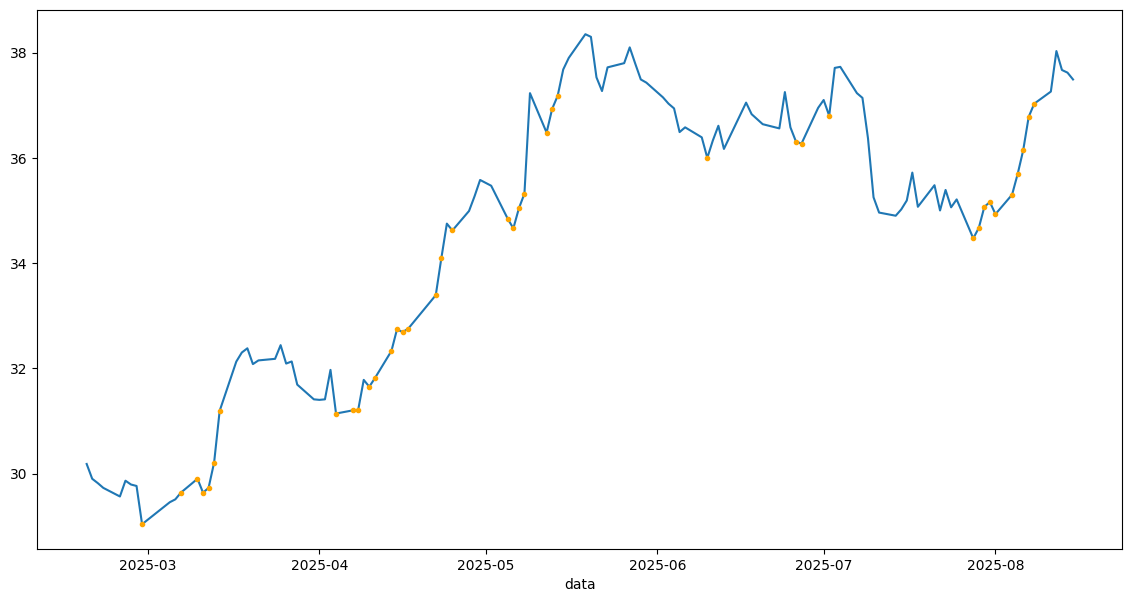

In [64]:
fig, ax = plt.subplots(figsize=(14, 7))

df['close'].plot(ax=ax) 


df[df['Target']==1]['close'].plot(ax=ax, style='o', markersize=3, label='Target', color='orange')

# Tentativa de visualizar a correlação de algumas features

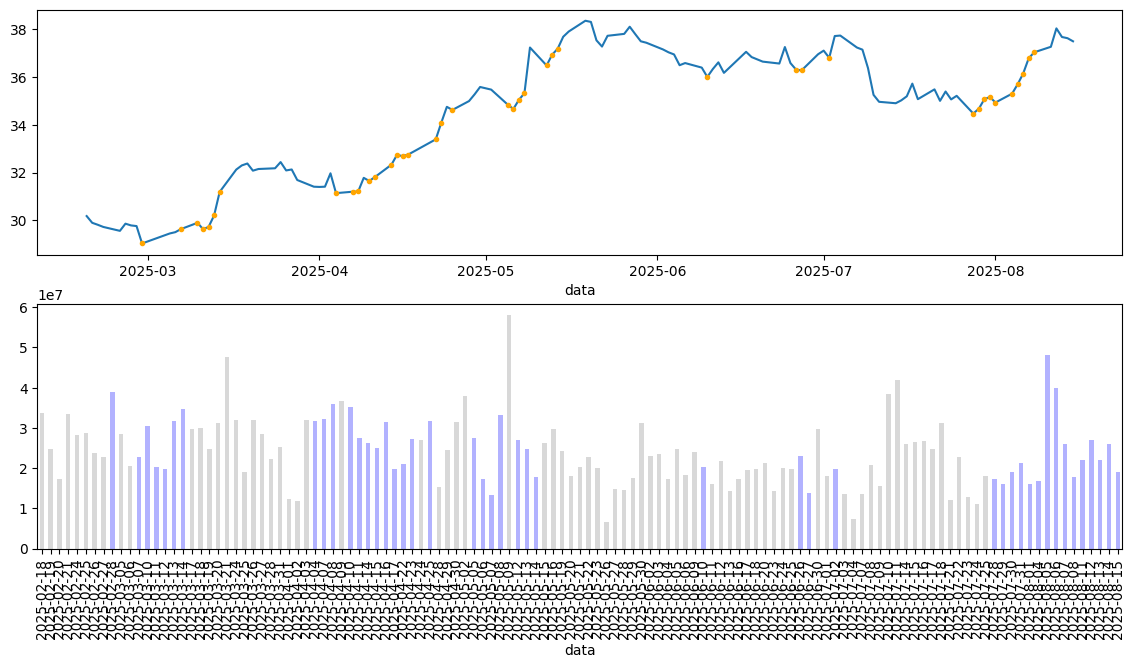

In [65]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))



df['close'].plot(ax=ax1) 


df[df['Target']==1]['close'].plot(ax=ax1, style='o', markersize=3, label='Target', color='orange')

color = ['gray' if x == 0 else 'blue' for x in df['Target']]
df['volume'].plot.bar(ax=ax2, alpha=0.3, color=color)

plt.show()

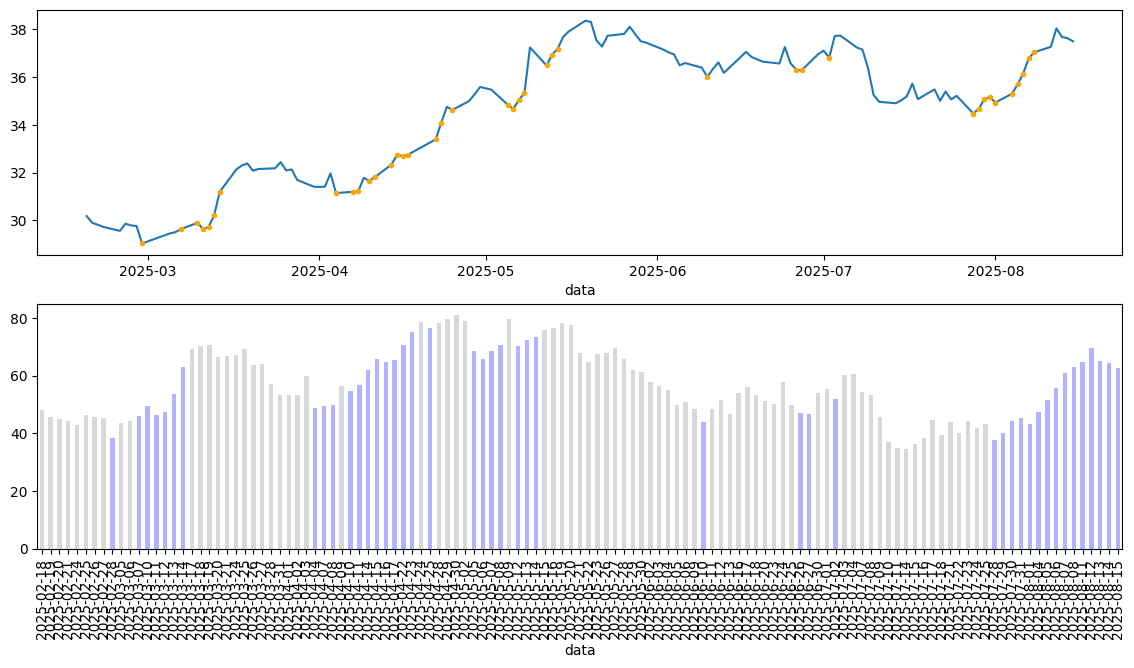

In [66]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))



df['close'].plot(ax=ax1) 


df[df['Target']==1]['close'].plot(ax=ax1, style='o', markersize=3, label='Target', color='orange')


df['rsi'].plot.bar(ax=ax2, alpha=0.3, color=color)

plt.show()

# Montagem de um X simplificado

In [67]:
from sklearn.linear_model import LinearRegression

def preparar_X_y_agregado(df: pd.DataFrame, dias_entrada: int, dropna: bool = True, tipo_drop_na: str = 'linhas', papel: str = None) -> tuple:
    """
    Prepara os dataframes X e y para o modelo, usando uma janela deslizante de 'dias_entrada'.
    Assume que indicadores técnicos, incluindo ADX e Bandas de Bollinger, já estão calculados no df de entrada,
    tanto para o papel principal quanto para os papéis adicionais.
    """

    def inclinacao_trend(serie: pd.Series) -> float:
        serie_limpa = serie.dropna()
        if len(serie_limpa) < 2 or len(serie_limpa) < len(serie) * 0.7: return np.nan
        y_val = serie_limpa.values.reshape(-1, 1)
        x_val = np.arange(len(serie_limpa)).reshape(-1, 1)
        try:
            modelo = LinearRegression().fit(x_val, y_val)
            return modelo.coef_[0][0]
        except ValueError: return np.nan


    def retorno_desde_ultima_mudanca_sinal(series: pd.Series) -> float:
        if len(series) < 2: return np.nan
        returns = series.pct_change()
        sinais = np.sign(returns)
        mudancas = sinais.diff().fillna(0) != 0
        if not mudancas.any(): return np.nan
        idx_ultima_mudanca_real = mudancas[mudancas].index[-1]
        try:
            pos_na_serie_original = series.index.get_indexer_for([idx_ultima_mudanca_real])[0]
        except (KeyError, IndexError): return np.nan
        valor_inicial = series.iloc[pos_na_serie_original]
        valor_final = series.iloc[-1]
        if pd.isna(valor_inicial) or pd.isna(valor_final) or valor_inicial == 0: return np.nan
        return (valor_final / valor_inicial) - 1

    X_rows, y_list, indices_X = [], [], []
    
    soma_volume_janelas_target_1 = []
    ret_acumulado_ultimos_3_dias_target_1 = []
    bbands_largura_pct_mean_target_1 = []
    adx_mean_target_1 = []

    # --- Loop Principal sobre as Janelas ---
    for i in range(dias_entrada - 1, len(df)):        
        janela = df.iloc[i - dias_entrada + 1:i + 1].copy()
        # Alvo    
        alvo = df.iloc[i]['Target']        

        linha = {}
        

        linha['volume_soma'] = janela['volume'].sum() 
        #linha['volume_media'] = janela['volume'].mean()
        #linha['volume_std'] = janela['volume'].std()
        linha['volume_trend'] = inclinacao_trend(janela['volume'])

        s_volumes = pd.Series(soma_volume_janelas_target_1)
        # comparar a soma desta janela com 1 e 3 quartis da s_volumes
        volume_soma_q1 = s_volumes.quantile(0.25) if not s_volumes.empty else np.nan
        volume_soma_q3 = s_volumes.quantile(0.75) if not s_volumes.empty else np.nan
        linha['volume_soma_menor_q1'] = linha['volume_soma'] < volume_soma_q1
        linha['volume_soma_maior_q3'] = linha['volume_soma'] > volume_soma_q3
        linha['volume_entre_q1_q3'] = (linha['volume_soma'] >= volume_soma_q1) and (linha['volume_soma'] <= volume_soma_q3)
        

        linha['retorno_acumulado'] = (janela['close'].iloc[-1] / janela['close'].iloc[0]) - 1
        linha['retorno_acumulado_ultimos_3_dias'] = (janela['close'].iloc[-1] / janela['close'].iloc[-3]) - 1
        s_ret_acumulado_ultimos_3_dias_target_1 = pd.Series(ret_acumulado_ultimos_3_dias_target_1)
        ret_acumulado_ultimos_3_dias_q1 = s_ret_acumulado_ultimos_3_dias_target_1.quantile(0.25) if not s_ret_acumulado_ultimos_3_dias_target_1.empty else np.nan
        ret_acumulado_ultimos_3_dias_q3 = s_ret_acumulado_ultimos_3_dias_target_1.quantile(0.75) if not s_ret_acumulado_ultimos_3_dias_target_1.empty else np.nan
        linha['retorno_acumulado_ultimos_3_dias_menor_q1'] = linha['retorno_acumulado_ultimos_3_dias'] < ret_acumulado_ultimos_3_dias_q1
        linha['retorno_acumulado_ultimos_3_dias_maior_q3'] = linha['retorno_acumulado_ultimos_3_dias'] > ret_acumulado_ultimos_3_dias_q3
        linha['retorno_acumulado_ultimos_3_dias_entre_q1_q3'] = (linha['retorno_acumulado_ultimos_3_dias'] >= ret_acumulado_ultimos_3_dias_q1) and (linha['retorno_acumulado_ultimos_3_dias'] <= ret_acumulado_ultimos_3_dias_q3)

        linha['retorno_acumulado_ultimos_5_dias'] = (janela['close'].iloc[-1] / janela['close'].iloc[-5]) - 1



        linha['close_trend'] = inclinacao_trend(janela['close'])
        linha['close_trend_positiva_volume_entre_q1_q3'] = linha['close_trend'] > 0 and linha['volume_entre_q1_q3'] 
        linha['close_trend_negativa_volume_entre_q1_q3'] = linha['close_trend'] < 0 and linha['volume_entre_q1_q3']
        linha['close_trend_positiva_volume_soma_maior_q3'] = linha['close_trend'] > 0 and linha['volume_soma_maior_q3']
        linha['close_trend_negativa_volume_soma_menor_q1'] = linha['close_trend'] < 0 and linha['volume_soma_menor_q1']
        linha['close_ultimo'] = janela['close'].iloc[-1]

        s_adx_mean_target_1 = pd.Series(adx_mean_target_1)
        adx_col_name = 'ADX_14'
        if adx_col_name in janela.columns:
            adx_series = janela[adx_col_name]
            linha['adx_ultimo'] = adx_series.iloc[-1] if not adx_series.empty else np.nan
            linha['adx_mean'] = adx_series.mean()
            linha['adx_trend'] = inclinacao_trend(adx_series)
            linha['tendencia_forte_adx25'] = 1 if linha.get('adx_ultimo', 0) > 25 else 0

            linha['adx_mean_entre_q1_q3'] = (linha['adx_mean'] >= s_adx_mean_target_1.quantile(0.25)) and (linha['adx_mean'] <= s_adx_mean_target_1.quantile(0.75))

            dmp_col_name, dmn_col_name = 'DMP_14', 'DMN_14'
            if dmp_col_name in janela.columns and dmn_col_name in janela.columns:
                linha['tendencia_positiva_dominante'] = 1 if (janela[dmp_col_name].iloc[-1] > janela[dmn_col_name].iloc[-1]) else 0
        
        bb_width_col, bb_percent_col = 'BBB_20_2.0', 'BBP_20_2.0'
        if bb_width_col in janela.columns:
            linha['bbands_largura_pct_ultimo'] = janela[bb_width_col].iloc[-1] if not janela[bb_width_col].empty else np.nan
            linha['bbands_largura_pct_mean'] = janela[bb_width_col].mean()
            linha['bbands_largura_pct_trend'] = inclinacao_trend(janela[bb_width_col])

            s_bbands_largura_pct_mean_target_1 = pd.Series(bbands_largura_pct_mean_target_1)
            linha['bbands_largura_pct_entre_q1_q3'] = (linha['bbands_largura_pct_mean'] >= s_bbands_largura_pct_mean_target_1.quantile(0.25)) and (linha['bbands_largura_pct_mean'] <= s_bbands_largura_pct_mean_target_1.quantile(0.75))

        if bb_percent_col in janela.columns:
            linha['bbands_posicao_pct_ultimo'] = janela[bb_percent_col].iloc[-1] if not janela[bb_percent_col].empty else np.nan
            linha['bbands_exaustao_compra'] = 1 if linha.get('bbands_posicao_pct_ultimo', 0.5) > 1.0 else 0
            linha['bbands_exaustao_venda'] = 1 if linha.get('bbands_posicao_pct_ultimo', 0.5) < 0.0 else 0




        X_rows.append(linha)
        y_list.append(alvo)
        indices_X.append(df.index[i])
        if alvo==1:
            soma_volume_janelas_target_1.append(linha['volume_soma'])
            ret_acumulado_ultimos_3_dias_target_1.append(linha['retorno_acumulado_ultimos_3_dias'])
            adx_mean_target_1.append(linha['adx_mean'])
            bbands_largura_pct_mean_target_1.append(linha['bbands_largura_pct_mean'])



    X_df = pd.DataFrame(X_rows, index=indices_X)
    if X_df.empty:
        y_series = pd.Series(dtype='float64')
    else:
        y_series = pd.Series(y_list, index=X_df.index)

    
    if dropna:
        if not X_df.empty:
            if tipo_drop_na == 'linhas':
                len_antes = len(X_df)
                X_df.dropna(axis=0, how='any', inplace=True)
                y_series = y_series.loc[X_df.index]
                if len(X_df) < len_antes:
                    print(f"INFO: {len_antes - len(X_df)} linha(s) removidas de X e y devido a NaNs (dropna='linhas').")
            elif tipo_drop_na == 'colunas':
                cols_antes = X_df.shape[1]
                X_df.dropna(axis=1, how='any', inplace=True)
                if X_df.shape[1] < cols_antes:
                    print(f"INFO: {cols_antes - X_df.shape[1]} coluna(s) removidas de X devido a NaNs (dropna='colunas').")


    return X_df, y_series


In [ ]:

X, y = preparar_X_y_agregado(df, dias_entrada = dias_entrada, dropna = True, tipo_drop_na = 'linhas')
X.tail()

,volume_soma,volume_trend,volume_soma_menor_q1,volume_soma_maior_q3,volume_entre_q1_q3,retorno_acumulado,retorno_acumulado_ultimos_3_dias,retorno_acumulado_ultimos_3_dias_menor_q1,retorno_acumulado_ultimos_3_dias_maior_q3,retorno_acumulado_ultimos_3_dias_entre_q1_q3,retorno_acumulado_ultimos_5_dias,close_trend,close_trend_positiva_volume_entre_q1_q3,close_trend_negativa_volume_entre_q1_q3,close_trend_positiva_volume_soma_maior_q3,close_trend_negativa_volume_soma_menor_q1,close_ultimo,adx_ultimo,adx_mean,adx_trend,tendencia_forte_adx25,adx_mean_entre_q1_q3,tendencia_positiva_dominante,bbands_largura_pct_ultimo,bbands_largura_pct_mean,bbands_largura_pct_trend,bbands_largura_pct_entre_q1_q3,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda
2025-08-11,325541700,9.973339e+05,True,False,False,0.064571,0.013051,False,False,True,0.043990,0.152714,False,False,False,False,37.259998,20.236621,18.119100,-0.065846,0,False,1,8.372408,8.790524,-0.447551,False,1.098512,1,0
2025-08-12,329893600,1.156918e+06,False,False,True,0.074597,0.027005,False,True,False,0.052297,0.199321,True,False,False,False,38.029999,22.288195,18.327395,0.068229,0,False,1,10.306018,8.769405,-0.357313,False,1.152862,1,0
2025-08-13,338967900,8.958736e+05,False,False,True,0.074444,0.011004,False,False,True,0.024198,0.237250,True,False,False,False,37.669998,24.193227,18.682288,0.230373,0,False,1,11.327194,8.809525,-0.237483,False,0.972445,0,0
2025-08-14,353879200,6.541082e+05,False,False,True,0.068446,-0.010781,True,False,False,0.015933,0.256357,True,False,False,False,37.619999,25.101984,19.114923,0.388871,1,True,1,12.169982,8.887421,-0.090842,False,0.905329,0,0
2025-08-15,354859700,3.779111e+05,False,False,True,0.087612,-0.004778,False,False,True,0.006173,0.267357,True,False,False,False,37.490002,25.945829,19.651253,0.524956,1,True,1,12.574784,8.981352,0.066439,False,0.835473,0,0


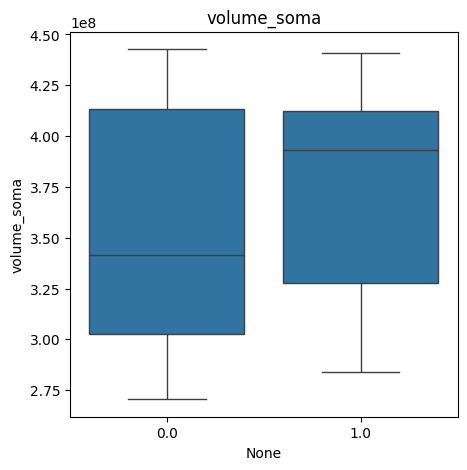

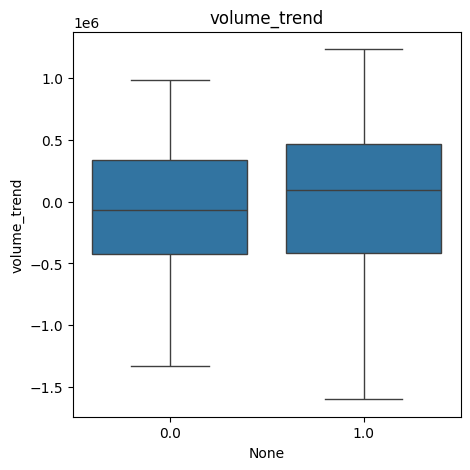

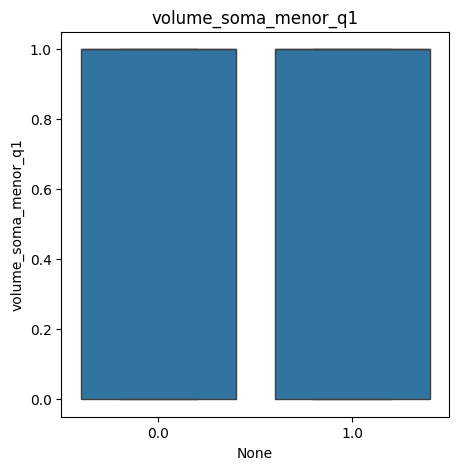

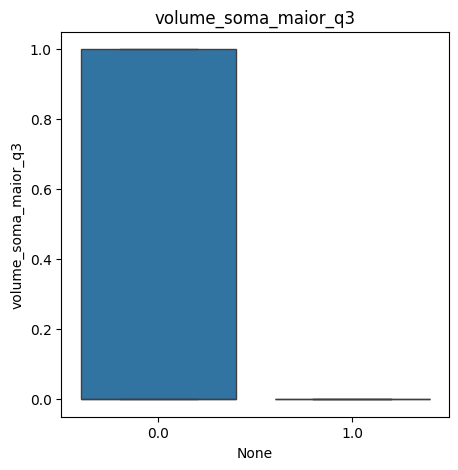

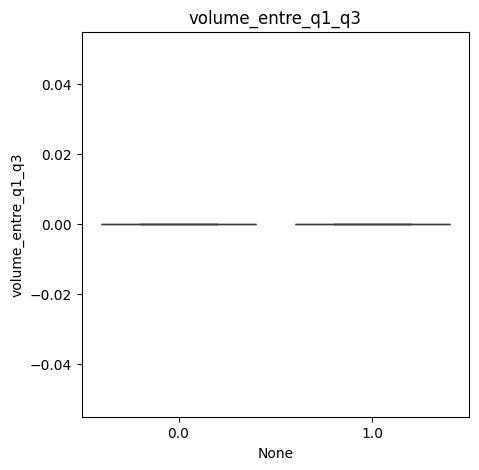

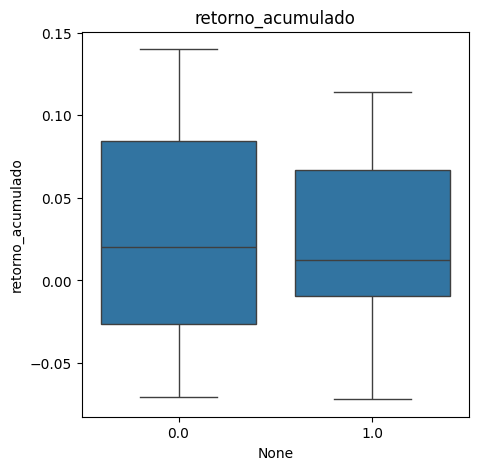

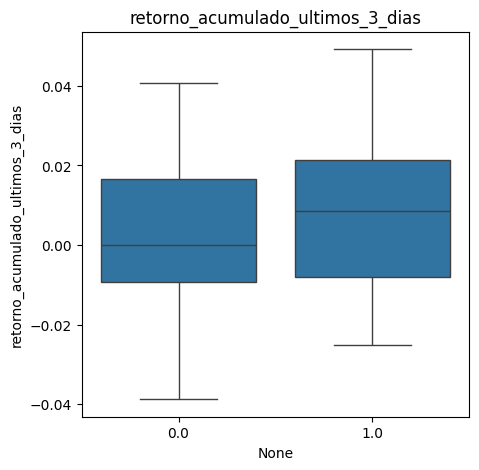

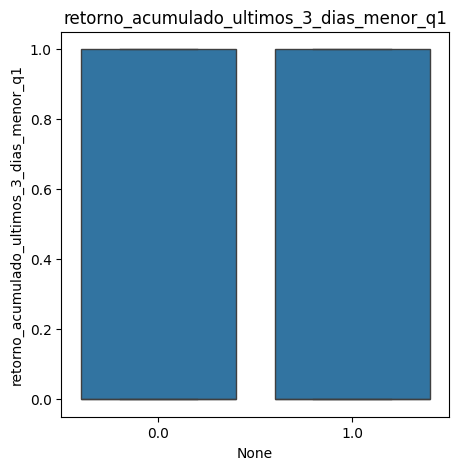

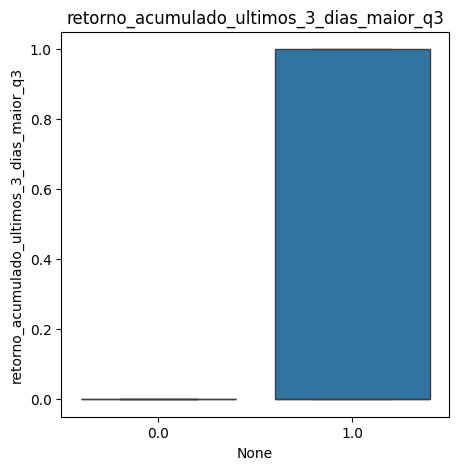

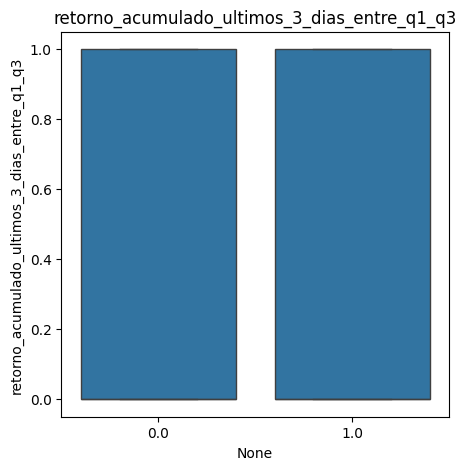

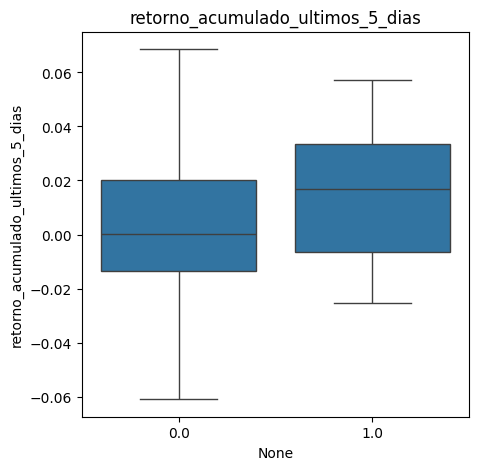

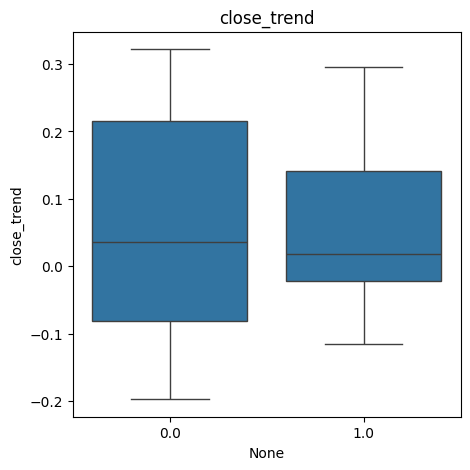

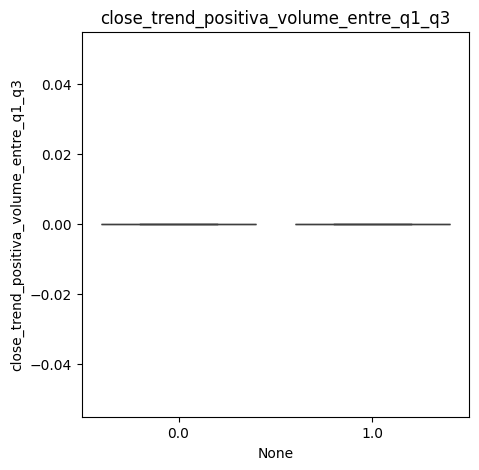

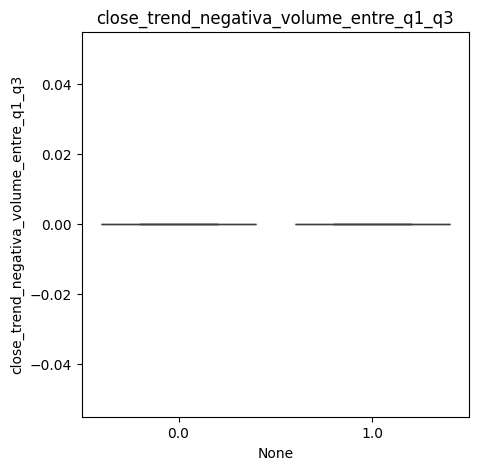

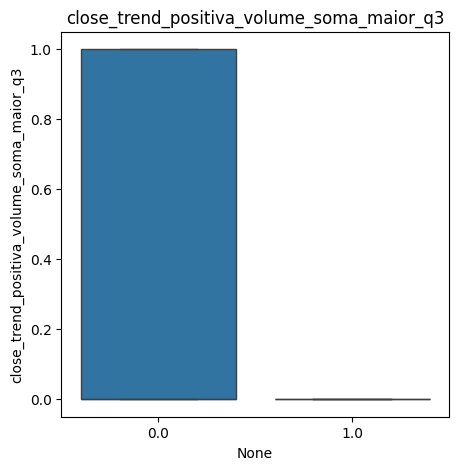

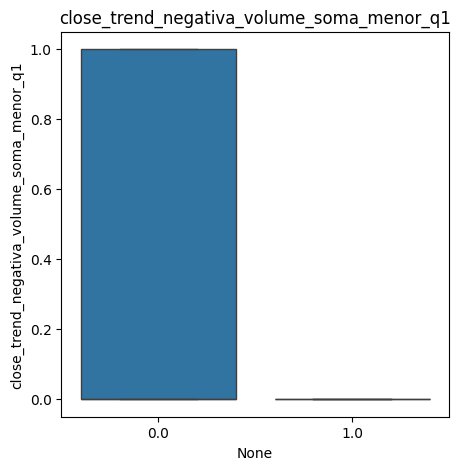

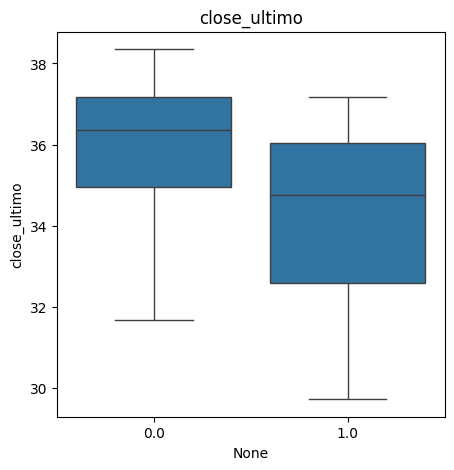

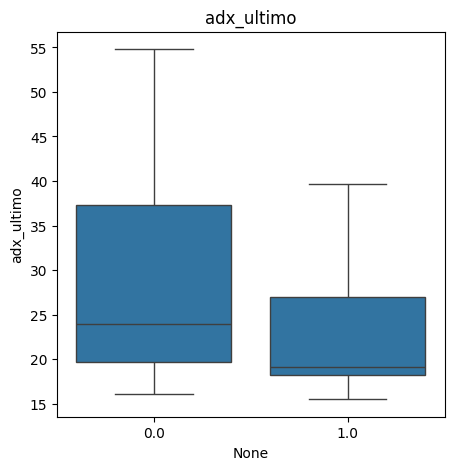

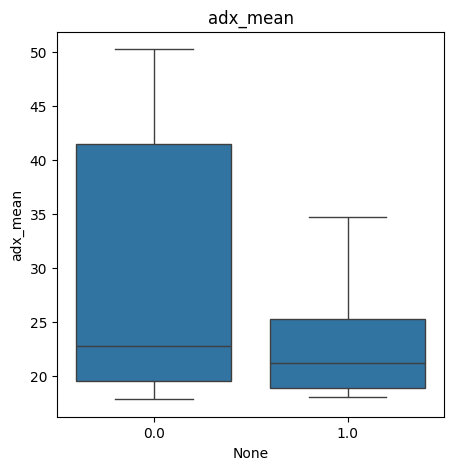

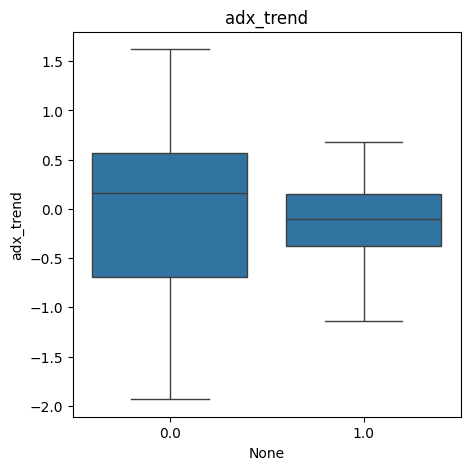

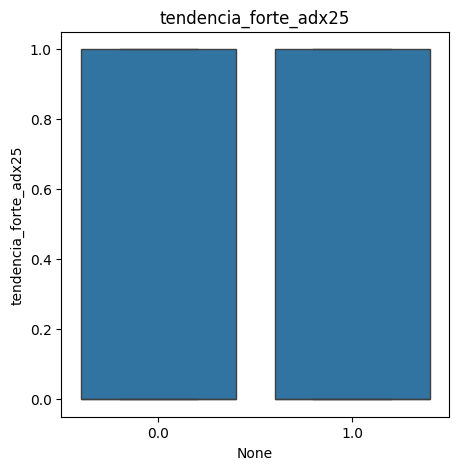

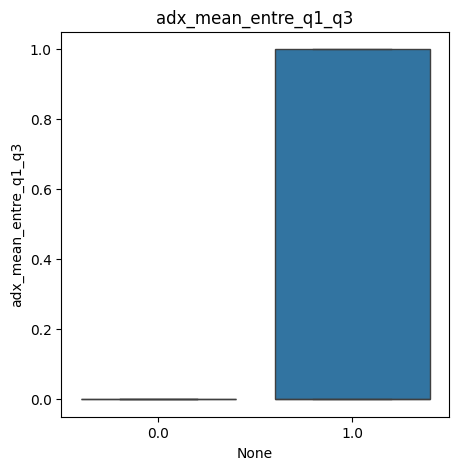

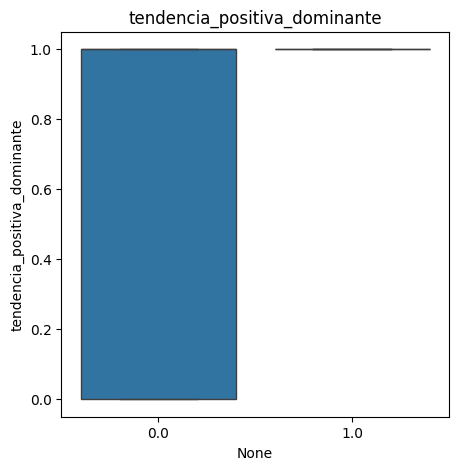

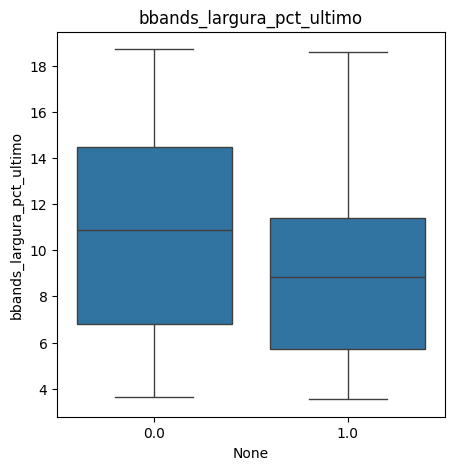

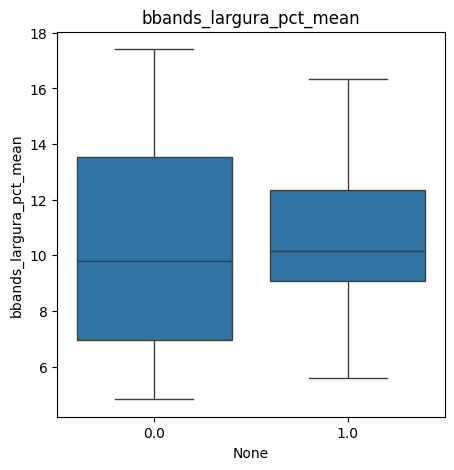

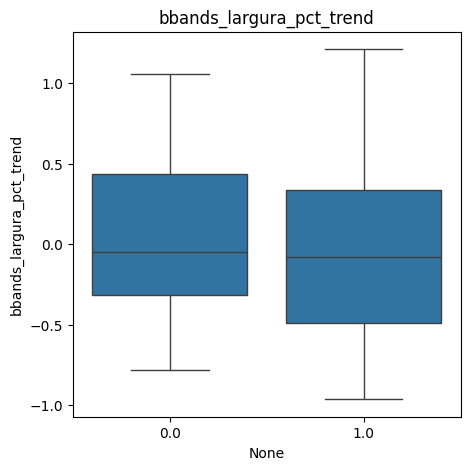

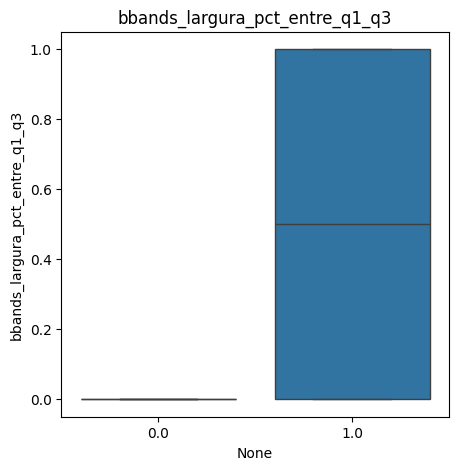

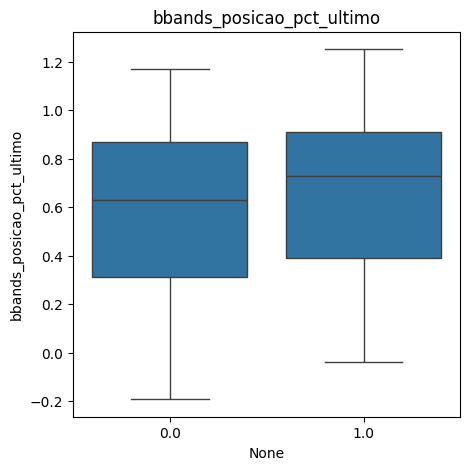

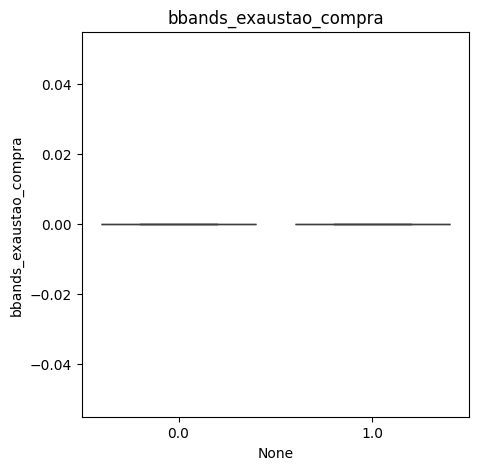

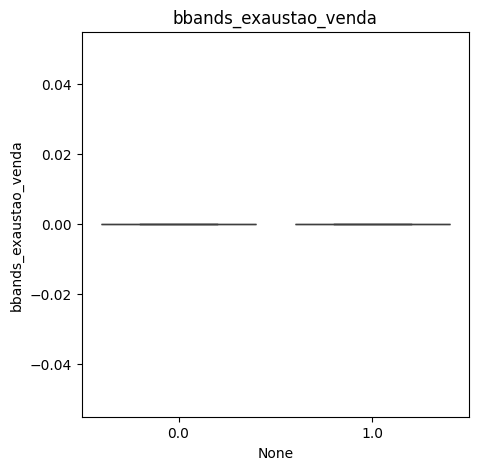

In [69]:
# boxplot de cada coluna quebrando por y

colunas = X.columns.tolist()
for coluna in colunas:
    plt.figure(figsize=(5, 5))
    sns.boxplot(x=y, y=X[coluna], showfliers=False)
    plt.title(coluna)
    plt.show()



In [70]:
def countplot_target_por_categoria(X, y, coluna):
        
    # Exemplo de como criar e plotar
    # Supondo que X_df_final e y_series_final são os resultados da sua função
    df_para_plot = pd.DataFrame({
        coluna: X[coluna],
        'Target': y
    })

    plt.figure(figsize=(8, 6))
    sns.countplot(data=df_para_plot, x=coluna, hue='Target')
    plt.title(f'Contagem de Target por {coluna}')
    plt.xlabel(coluna)
    plt.ylabel('Contagem de Ocorrências')
    plt.xticks([0, 1], ['Não (False)', 'Sim (True)']) # Rótulos mais claros
    plt.legend(title='Resultado Real (Target)')
    plt.show()

In [71]:
X.columns

Index(['volume_soma', 'volume_trend', 'volume_soma_menor_q1',
       'volume_soma_maior_q3', 'volume_entre_q1_q3', 'retorno_acumulado',
       'retorno_acumulado_ultimos_3_dias',
       'retorno_acumulado_ultimos_3_dias_menor_q1',
       'retorno_acumulado_ultimos_3_dias_maior_q3',
       'retorno_acumulado_ultimos_3_dias_entre_q1_q3',
       'retorno_acumulado_ultimos_5_dias', 'close_trend',
       'close_trend_positiva_volume_entre_q1_q3',
       'close_trend_negativa_volume_entre_q1_q3',
       'close_trend_positiva_volume_soma_maior_q3',
       'close_trend_negativa_volume_soma_menor_q1', 'close_ultimo',
       'adx_ultimo', 'adx_mean', 'adx_trend', 'tendencia_forte_adx25',
       'adx_mean_entre_q1_q3', 'tendencia_positiva_dominante',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_mean',
       'bbands_largura_pct_trend', 'bbands_largura_pct_entre_q1_q3',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exaustao_venda'],
      dtype='object')

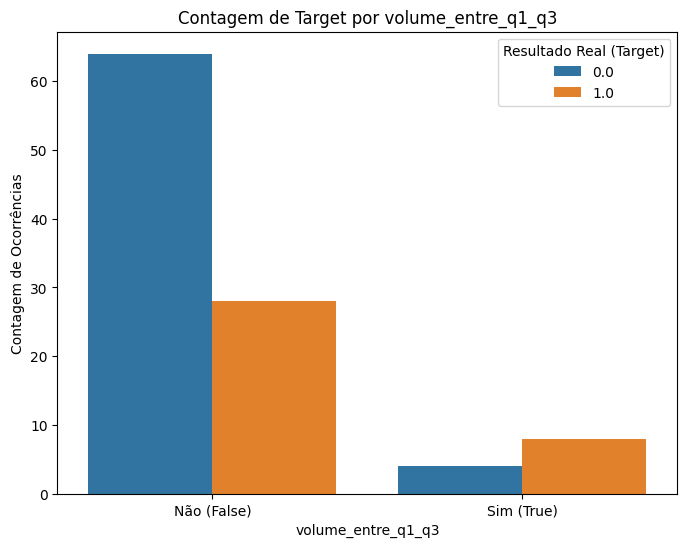

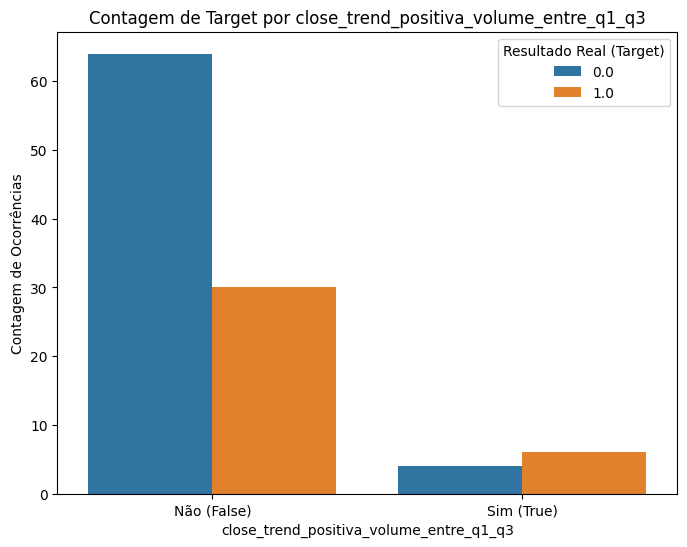

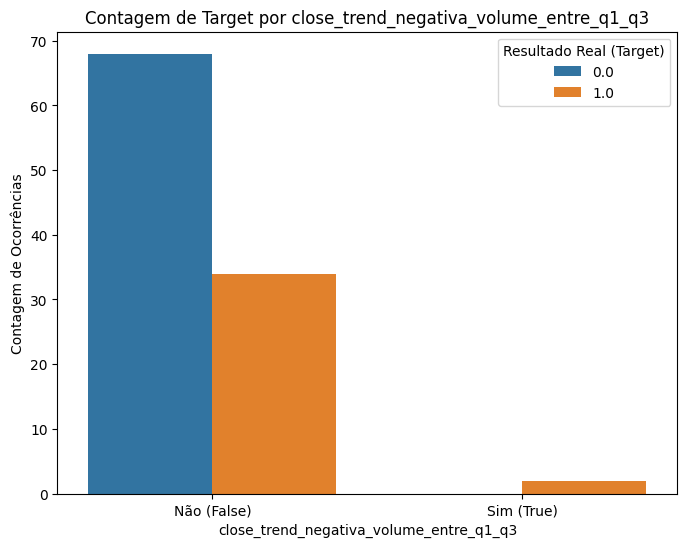

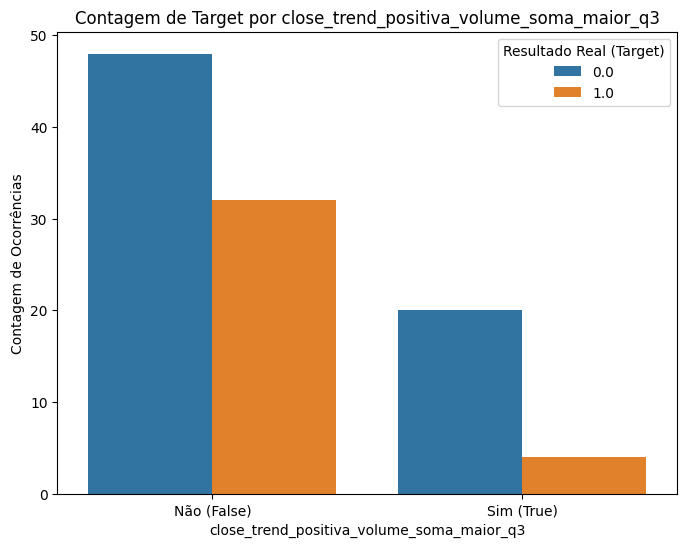

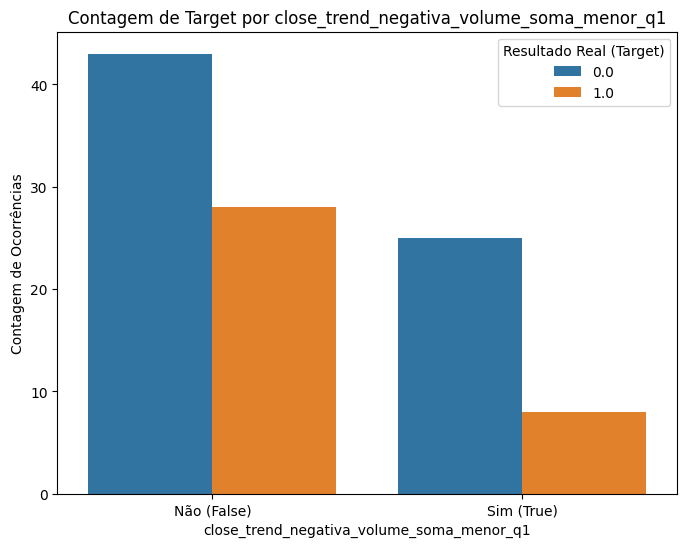

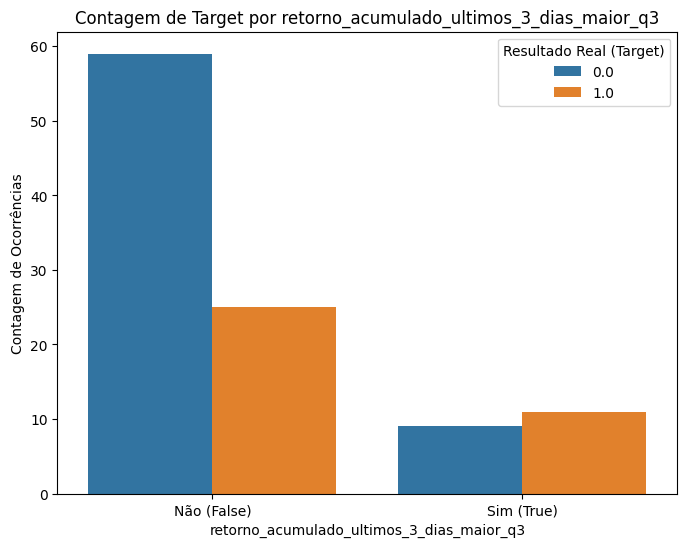

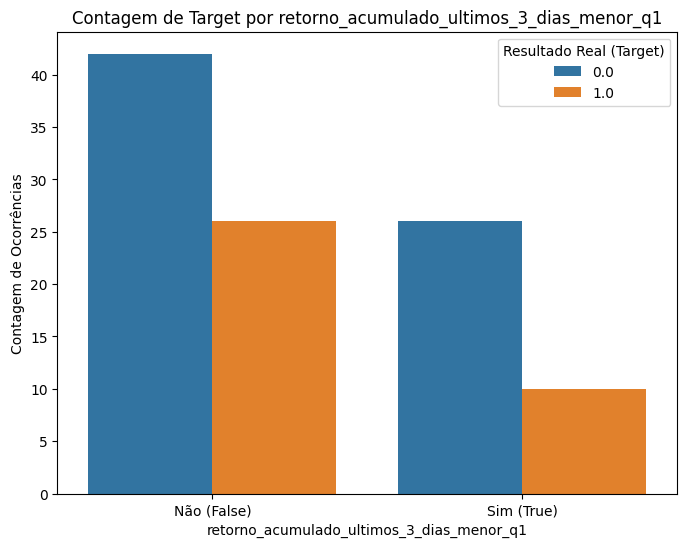

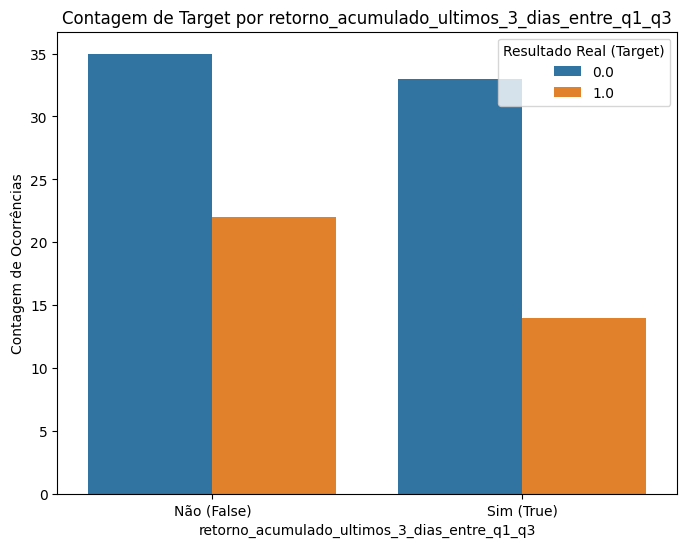

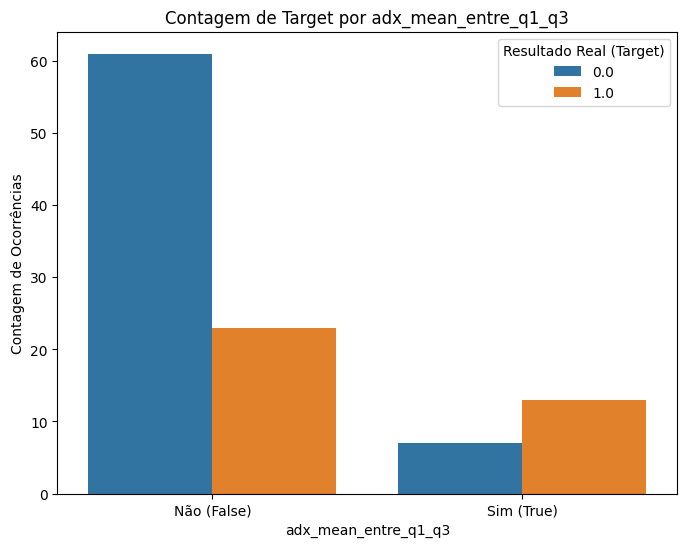

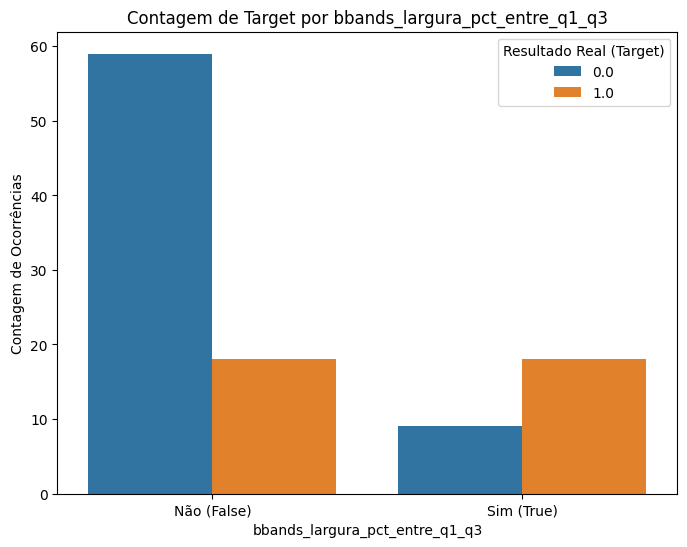

In [72]:
variaveis_categoricas = ['volume_entre_q1_q3'
                         , 'close_trend_positiva_volume_entre_q1_q3'
                         , 'close_trend_negativa_volume_entre_q1_q3'
                         , 'close_trend_positiva_volume_soma_maior_q3'
                         , 'close_trend_negativa_volume_soma_menor_q1'
                         , 'retorno_acumulado_ultimos_3_dias_maior_q3'
                         , 'retorno_acumulado_ultimos_3_dias_menor_q1'
                        , 'retorno_acumulado_ultimos_3_dias_entre_q1_q3'
                        , 'adx_mean_entre_q1_q3'
                        , 'bbands_largura_pct_entre_q1_q3'
                        ]

for v in variaveis_categoricas:
    countplot_target_por_categoria(X, y, v)


In [73]:
X.columns

Index(['volume_soma', 'volume_trend', 'volume_soma_menor_q1',
       'volume_soma_maior_q3', 'volume_entre_q1_q3', 'retorno_acumulado',
       'retorno_acumulado_ultimos_3_dias',
       'retorno_acumulado_ultimos_3_dias_menor_q1',
       'retorno_acumulado_ultimos_3_dias_maior_q3',
       'retorno_acumulado_ultimos_3_dias_entre_q1_q3',
       'retorno_acumulado_ultimos_5_dias', 'close_trend',
       'close_trend_positiva_volume_entre_q1_q3',
       'close_trend_negativa_volume_entre_q1_q3',
       'close_trend_positiva_volume_soma_maior_q3',
       'close_trend_negativa_volume_soma_menor_q1', 'close_ultimo',
       'adx_ultimo', 'adx_mean', 'adx_trend', 'tendencia_forte_adx25',
       'adx_mean_entre_q1_q3', 'tendencia_positiva_dominante',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_mean',
       'bbands_largura_pct_trend', 'bbands_largura_pct_entre_q1_q3',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exaustao_venda'],
      dtype='object')

In [74]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np # Para criar dados de exemplo

def plotar_interacao_features(df_features_e_target: pd.DataFrame,
                               feature_x: str,
                               feature_y: str,
                               target_col: str):
    """
    Cria um scatterplot para visualizar a interação de duas features
    em relação a um alvo binário.

    Args:
        df_features_e_target (pd.DataFrame): DataFrame contendo as features e a coluna do alvo.
        feature_x (str): Nome da coluna para o eixo X.
        feature_y (str): Nome da coluna para o eixo Y.
        target_col (str): Nome da coluna do alvo (ex: 'Target').
    """
    if not all(col in df_features_e_target.columns for col in [feature_x, feature_y, target_col]):
        print(f"ERRO: DataFrame não contém todas as colunas necessárias: {feature_x}, {feature_y}, {target_col}")
        return

    plt.figure(figsize=(5, 5))

    # seaborn.scatterplot é perfeito para isso.
    # 'hue' é o parâmetro que define a cor dos pontos com base em uma coluna.
    # 'style' pode ser usado para variar o formato do marcador (ex: círculo vs. X).
    # 'alpha' controla a transparência, útil se houver muitos pontos sobrepostos.
    sns.scatterplot(
        data=df_features_e_target,
        x=feature_x,
        y=feature_y,
        hue=target_col,
        style=target_col,
        alpha=0.7,
        palette={0: 'blue', 1: 'orange'} # Define cores para 0 e 1
    )

    plt.title(f'Interação entre "{feature_x}" e "{feature_y}"\nColorido por "{target_col}"', fontsize=16)
    plt.xlabel(feature_x, fontsize=12)
    plt.ylabel(feature_y, fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(title='Resultado Real (Target)')
    plt.show()


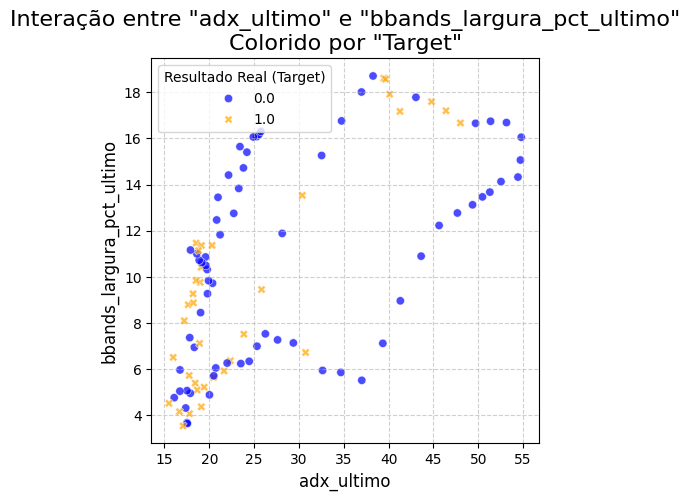

In [75]:
plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x='adx_ultimo',
        feature_y='bbands_largura_pct_ultimo',
        target_col='Target'
    )


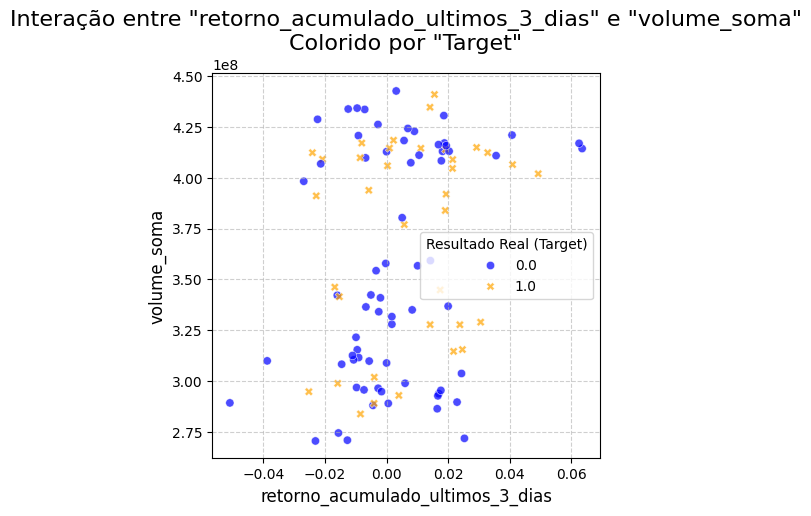

In [76]:
plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x='retorno_acumulado_ultimos_3_dias',
        feature_y='volume_soma',
        target_col='Target'
    )

# Tentativa de treinar um modelo simples

In [ ]:
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

In [ ]:
X_train.tail()

,volume_soma,volume_trend,volume_soma_menor_q1,volume_soma_maior_q3,volume_entre_q1_q3,retorno_acumulado,retorno_acumulado_ultimos_3_dias,retorno_acumulado_ultimos_3_dias_menor_q1,retorno_acumulado_ultimos_3_dias_maior_q3,retorno_acumulado_ultimos_3_dias_entre_q1_q3,retorno_acumulado_ultimos_5_dias,close_trend,close_trend_positiva_volume_entre_q1_q3,close_trend_negativa_volume_entre_q1_q3,close_trend_positiva_volume_soma_maior_q3,close_trend_negativa_volume_soma_menor_q1,close_ultimo,adx_ultimo,adx_mean,adx_trend,tendencia_forte_adx25,adx_mean_entre_q1_q3,tendencia_positiva_dominante,bbands_largura_pct_ultimo,bbands_largura_pct_mean,bbands_largura_pct_trend,bbands_largura_pct_entre_q1_q3,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda
2025-03-25,422881710,573107.071429,False,True,False,0.101358,0.009020,False,False,True,0.001853,0.262523,False,False,True,False,32.439999,25.285180,20.801386,0.438414,1,False,1,16.078222,11.635646,0.436622,False,0.863886,0,0
2025-03-26,426236960,676040.250000,False,True,False,0.087462,-0.002797,True,False,False,0.000312,0.245899,False,False,True,False,32.090000,25.527269,21.213316,0.515045,1,False,1,16.167028,12.041836,0.505293,False,0.764662,0,0
2025-03-27,434287770,451513.678571,False,True,False,0.084141,-0.009556,True,False,False,-0.000622,0.222422,False,False,True,False,32.130001,25.752066,21.621033,0.583456,1,False,1,16.303435,12.435859,0.564726,False,0.746925,0,0
2025-03-28,433848980,106149.571429,False,True,False,0.059866,-0.012465,True,False,False,-0.015227,0.182221,False,False,True,False,31.690001,24.909392,21.980019,0.605767,0,False,1,16.063814,12.813296,0.597322,False,0.642351,0,0
2025-03-31,428778540,61094.357143,False,True,False,0.059847,-0.022409,True,False,False,-0.031751,0.135218,False,False,True,False,31.410000,23.417075,22.246431,0.568576,0,False,1,15.645490,13.177007,0.593171,False,0.571220,0,0


In [79]:
X_train.columns

Index(['volume_soma', 'volume_trend', 'volume_soma_menor_q1',
       'volume_soma_maior_q3', 'volume_entre_q1_q3', 'retorno_acumulado',
       'retorno_acumulado_ultimos_3_dias',
       'retorno_acumulado_ultimos_3_dias_menor_q1',
       'retorno_acumulado_ultimos_3_dias_maior_q3',
       'retorno_acumulado_ultimos_3_dias_entre_q1_q3',
       'retorno_acumulado_ultimos_5_dias', 'close_trend',
       'close_trend_positiva_volume_entre_q1_q3',
       'close_trend_negativa_volume_entre_q1_q3',
       'close_trend_positiva_volume_soma_maior_q3',
       'close_trend_negativa_volume_soma_menor_q1', 'close_ultimo',
       'adx_ultimo', 'adx_mean', 'adx_trend', 'tendencia_forte_adx25',
       'adx_mean_entre_q1_q3', 'tendencia_positiva_dominante',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_mean',
       'bbands_largura_pct_trend', 'bbands_largura_pct_entre_q1_q3',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exaustao_venda'],
      dtype='object')

In [ ]:
lista_colunas = ['volume_soma', 'volume_trend', 'volume_entre_q1_q3'
                 , 'retorno_acumulado', 'retorno_acumulado_ultimos_3_dias', 'retorno_acumulado_ultimos_3_dias_maior_q3'
                 , 'close_trend_positiva_volume_entre_q1_q3'
                  , 'adx_mean_entre_q1_q3'
                , 'bbands_largura_pct_entre_q1_q3'
                 ]#, 'close_trend_negativa_volume_entre_q1_q3']
X_train = X_train[lista_colunas]
X_validacao = X_validacao[lista_colunas]

from sklearn.preprocessing import StandardScaler

# Antes de treinar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validacao_scaled = scaler.transform(X_validacao)

AUC no treino: 0.000
AUC na validação: 0.427
Diferença AUC (Treino - Validação): -0.427
PR AUC no treino: 0.000
PR AUC na validação: 0.275
Diferença PR AUC (Treino - Validação): -0.275
F1 Score no treino: 0.000
F1 Score na validação: 0.333


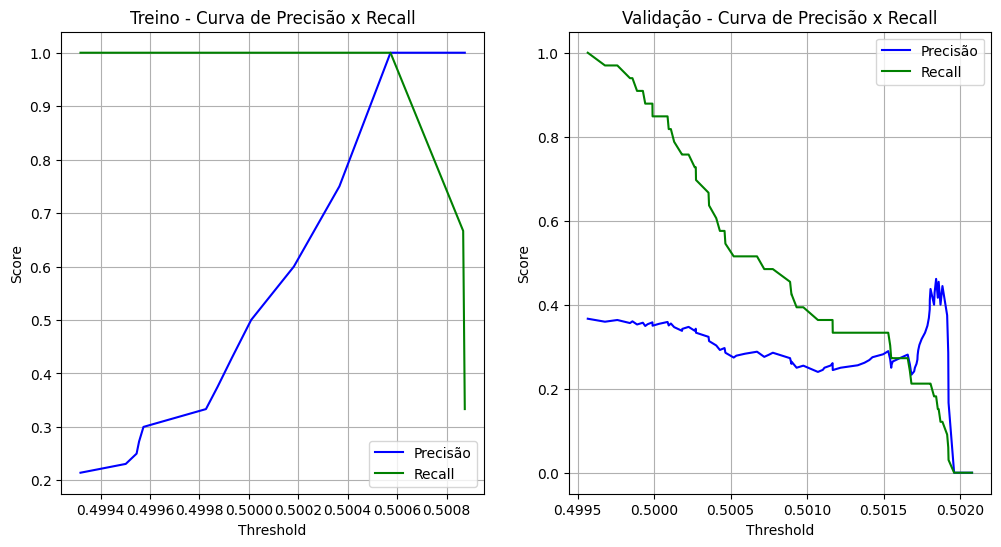

(0,
 np.float64(0.4274261199587138),
 np.float64(-0.4274261199587138),
 0,
 np.float64(0.27542195683551407),
 0,
 np.float64(0.33311680512051106))

In [81]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.0001)
modelo_rl.fit(X_train_scaled, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train_scaled, y_train, X_validacao_scaled, y_validacao)

In [82]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(20)

,Feature,importancia,importancia_abs
3,retorno_acumulado,-0.000730,0.000730
0,volume_soma,-0.000637,0.000637
1,volume_trend,-0.000491,0.000491
5,retorno_acumulado_ultimos_3_dias_maior_q3,0.000375,0.000375
4,retorno_acumulado_ultimos_3_dias,0.000228,0.000228
2,volume_entre_q1_q3,0.000000,0.000000
6,close_trend_positiva_volume_entre_q1_q3,0.000000,0.000000
7,adx_mean_entre_q1_q3,0.000000,0.000000
8,bbands_largura_pct_entre_q1_q3,0.000000,0.000000


# Combinação em pares de variáveis para tentar identificar "ilhas"

In [83]:
X.shape

(109, 30)

In [84]:
df.shape

(123, 142)

In [85]:
dias_entrada

15

In [86]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.701639
1.0    0.298361
Name: proportion, dtype: float64

In [87]:
df.shape

(615, 142)

In [88]:
X, y = pp.preparar_X_y_agregado(df, dias_entrada=dias_entrada, dropna=True, tipo_drop_na='linhas', papel=papel)
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
X_train.shape

c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:784: Runtim

INFO: 199 linha(s) removidas de X e y devido a NaNs.


(307, 88)

In [89]:
X.columns

Index(['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
       'close_norm_trend', 'retorno_mean', 'retorno_std', 'dias_alta_pct',
       'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg',
       'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo',
       'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend',
       'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo',
       'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std',
       'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo',
       'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exau

# criar pares de colunas para plotar interações
colunas = X.columns.tolist()
pares_colunas = [(coluna_x, coluna_y) for i, coluna_x in enumerate(colunas) for coluna_y in colunas[i+1:]]

#for coluna_x, coluna_y in pares_colunas:
    plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x=coluna_x,
        feature_y=coluna_y,
        target_col='Target'
    )

# Decisiontree

In [90]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

def encontrar_ilhas_com_arvore_decisao(
        X_treino: pd.DataFrame,
        y_treino: pd.Series,
        max_profundidade: int = 4,
        min_pureza_folha: float = 0.51, # Ex: queremos folhas com mais de 50% de sucesso
        min_amostras_folha: int = 15,    # Ex: e baseadas em pelo menos 15 amostras
        visualizar_arvore: bool = True
    ):
    """
    Usa uma árvore de decisão rasa para encontrar e extrair "ilhas" (regras)
    de alta probabilidade para o Target=1.

    Args:
        X_treino: DataFrame de features de treino.
        y_treino: Série de alvos de treino.
        max_profundidade: Profundidade máxima da árvore para manter as regras simples.
        min_pureza_folha: A proporção mínima de Target=1 em uma folha para ser considerada "promissora".
        min_amostras_folha: Número mínimo TOTAL de amostras em uma folha para ser considerada.
        visualizar_arvore: Se True, plota a árvore de decisão gerada.

    Returns:
        Um DataFrame com as regras promissoras e suas estatísticas.
    """
    print(f"\n--- Buscando 'Ilhas' com Decision Tree (max_depth={max_profundidade}) ---")
    print(f"Critérios: Pureza >= {min_pureza_folha:.0%}, Mínimo de {min_amostras_folha} amostras por folha.")
    
    # Treinar a árvore de decisão rasa
    # O min_samples_leaf na árvore já é um pré-filtro. A verificação posterior é uma garantia.
    arvore_simples = DecisionTreeClassifier(
        max_depth=max_profundidade,
        min_samples_leaf=min_amostras_folha,
        class_weight='balanced',
        random_state=42
    )
    arvore_simples.fit(X_treino, y_treino)

    # --- Visualizar a Árvore (Opcional, mas Útil) ---
    if visualizar_arvore:
        plt.figure(figsize=(24, 12)) # Tamanho maior para melhor visualização
        plot_tree(
            arvore_simples,
            feature_names=X_treino.columns.tolist(),
            class_names=['Nao_Sucesso', 'Sucesso'],
            filled=True,
            rounded=True,
            proportion=False, # Mostra contagens, não proporções
            precision=2,
            fontsize=10
        )
        plt.title(f"Árvore de Decisão para Identificação de Regras (max_depth={max_profundidade})", fontsize=16)
        plt.show()

    # --- Extrair Regras das Folhas ---
    tree_ = arvore_simples.tree_
    feature_names = X_treino.columns.tolist()
    regras_promissoras = []

    def extrair_caminho_e_regras(node_index, caminho_atual):
        # Se for uma folha (não tem filhos)
        if tree_.children_left[node_index] == tree_.children_right[node_index]:
            
            # O 'value' é um array 3D: [[[contagem_classe_0, contagem_classe_1, ...]]]
            # Corrigindo o acesso aos valores
            perc_classe0 = tree_.value[node_index][0][0]
            perc_classe1 = tree_.value[node_index][0][1]
            total_amostras_na_folha = tree_.n_node_samples[node_index] # Forma mais direta de pegar o total
            contagem_classe0 = perc_classe0 * total_amostras_na_folha
            contagem_classe1 = perc_classe1 * total_amostras_na_folha
            print(f"Folha {node_index}: {caminho_atual} -> Classe 0: {contagem_classe0}, Classe 1: {contagem_classe1}, Total: {total_amostras_na_folha}")

            # Verificação para evitar divisão por zero se a folha estiver vazia (improvável)
            if total_amostras_na_folha > 0:
                taxa_de_sucesso = contagem_classe1 / total_amostras_na_folha
                
                # Aplicar os filtros para decidir se a regra é "promissora"
                if taxa_de_sucesso >= min_pureza_folha and total_amostras_na_folha >= min_amostras_folha:
                    regra_str = " E ".join(caminho_atual) if caminho_atual else "Todas as amostras"
                    regras_promissoras.append({
                        'regra': regra_str,
                        'taxa_sucesso': taxa_de_sucesso,
                        'num_sucessos': contagem_classe1,
                        'num_total_amostras': total_amostras_na_folha
                    })
            return

        # Se não for uma folha, continuar recursivamente para os filhos
        feature_index = tree_.feature[node_index]
        feature_name = feature_names[feature_index]
        threshold_val = tree_.threshold[node_index]
        
        # Caminho da esquerda (condição <=)
        caminho_para_esquerda = caminho_atual + [f"{feature_name} <= {threshold_val:.4f}"]
        extrair_caminho_e_regras(tree_.children_left[node_index], caminho_para_esquerda)
        
        # Caminho da direita (condição >)
        caminho_para_direita = caminho_atual + [f"{feature_name} > {threshold_val:.4f}"]
        extrair_caminho_e_regras(tree_.children_right[node_index], caminho_para_direita)

    # Iniciar a extração recursiva a partir do nó raiz (índice 0)
    extrair_caminho_e_regras(0, [])
    
    if not regras_promissoras:
        print("\nNenhuma regra promissora encontrada com os critérios definidos.")
        return pd.DataFrame()
        
    df_regras = pd.DataFrame(regras_promissoras).sort_values(by=['taxa_sucesso', 'num_total_amostras'], ascending=[False, False])
    return df_regras


In [91]:
X.head()

,close_norm_mean,close_norm_std,close_norm_max,close_norm_min,close_norm_trend,retorno_mean,retorno_std,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,correl_retorno_volume,rsi_mean,rsi_std,rsi_ultimo,rsi_trend,macd_mean,macd_std,macd_ultimo,macd_trend,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_signal_trend,macd_hist_mean,macd_hist_std,macd_hist_ultimo,macd_hist_trend,obv_mean,obv_std,obv_ultimo,obv_trend,cmf_mean,cmf_std,cmf_ultimo,cmf_trend,atr_pct_mean,atr_pct_std,atr_pct_ultimo,atr_pct_trend,adx_ultimo,adx_trend,tendencia_forte_adx25,bbands_largura_pct_ultimo,bbands_largura_pct_trend,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda,adc_close_norm_trend_BBAS3,adc_correl_com_principal_BBAS3,adc_adx_ultimo_BBAS3,adc_close_norm_trend_BBDC4,adc_correl_com_principal_BBDC4,adc_adx_ultimo_BBDC4,adc_close_norm_trend_SANB11,adc_correl_com_principal_SANB11,adc_adx_ultimo_SANB11,adc_close_norm_mean_geral_ultimo,selic_ultimo,selic_comparacao_anterior,selic_dias_desde_mudanca,ipca_ultimo,ipca_comparacao_anterior,ipca_dias_desde_mudanca,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,close_norm_vs_adc_norm_mean_geral,retorno_acumulado_norm,dia_semana_0,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,feriado,proximo_dia_util
2024-01-09,1.198862,0.013702,1.223302,1.1798,-0.000150,0.000960,0.010667,0.533333,0.466667,0.008899,-0.008113,2.444663e+07,6.440476e+06,-678969.500000,-0.147781,0.473092,70.004466,6.657181,60.717173,-1.039312,0.765113,0.071972,0.609348,-0.011626,0.782566,0.026146,0.713232,-0.003314,-0.017453,0.049360,-0.103884,-0.008313,5.842898e+08,4.341719e+07,576222680.0,6.009919e+06,0.218713,0.035430,0.206870,0.000705,0.016909,0.000664,0.016897,-0.000096,39.648374,-0.541255,1,7.661440,-0.033137,0.634761,0,0,-0.001529,0.363549,20.036705,-0.006062,0.411380,32.141185,-0.000352,0.625668,29.262044,1.096366,11.75,-1.0,27,0.42,-1.0,12,4.8937,-0.000584,0.034678,0.000000,78.042857,1182.072687,0.000000,3997.0,0.640421,0.959303,0.000654,0.083105,-0.005047,0,1,0,0,0,0,True
2024-01-10,1.198257,0.014149,1.223302,1.1798,-0.000664,0.001184,0.010585,0.533333,0.466667,0.008899,-0.007634,2.313516e+07,7.037862e+06,-832456.821429,-0.520653,0.495959,69.076674,6.997373,60.245672,-1.164479,0.749168,0.086692,0.569197,-0.015288,0.775886,0.036380,0.684425,-0.005708,-0.026718,0.053907,-0.115228,-0.009580,5.886970e+08,3.702913e+07,565132920.0,3.094846e+06,0.214989,0.037137,0.173400,-0.000126,0.016786,0.000547,0.016455,-0.000067,37.613046,-0.717794,1,7.200152,-0.100358,0.603819,0,0,-0.001754,0.554162,18.974493,-0.006774,0.467314,31.507761,-0.001687,0.610766,28.901414,1.083940,11.75,-1.0,28,0.42,-1.0,13,4.8901,0.001128,0.031242,0.000000,-14.721429,1112.649378,-0.004610,3390.0,0.636923,0.963737,0.001023,0.092702,-0.011014,0,0,1,0,0,0,True
2024-01-11,1.197385,0.014587,1.223302,1.1798,-0.001026,0.000978,0.010537,0.533333,0.466667,0.008513,-0.007634,2.259099e+07,6.727868e+06,-636410.892857,-0.006625,0.491135,68.119196,7.072794,60.899633,-1.192187,0.730362,0.100294,0.535604,-0.018669,0.766781,0.047619,0.654661,-0.008301,-0.036420,0.056676,-0.119057,-0.010368,5.925601e+08,3.325711e+07,587574240.0,1.379101e+06,0.214328,0.037389,0.196443,-0.000836,0.016687,0.000503,0.016216,-0.000055,35.585033,-0.903206,1,6.335879,-0.169515,0.609365,0,0,-0.001747,0.546386,18.252773,-0.007050,0.460235,31.262011,-0.002780,0.605609,28.721951,1.082325,11.75,-1.0,29,0.42,-1.0,14,4.8794,0.002756,0.026710,-0.002188,-89.242857,1150.840343,-0.006071,3545.0,0.656439,1.022087,0.001649,0.094434,-0.009952,0,0,0,1,0,0,True
2024-01-12,1.196542,0.015005,1.223302,1.1798,-0.001393,0.001017,0.010537,0.533333,0.466667,0.008587,-0.007634,2.262452e+07,6.748904e+06,-425072.607143,0.184743,0.491917,67.182756,6.968702,61.356061,-1.153166,0.709625,0.112487,0.506082,-

In [92]:
X.shape

(402, 88)


--- Buscando 'Ilhas' com Decision Tree (max_depth=2) ---
Critérios: Pureza >= 50%, Mínimo de 30 amostras por folha.


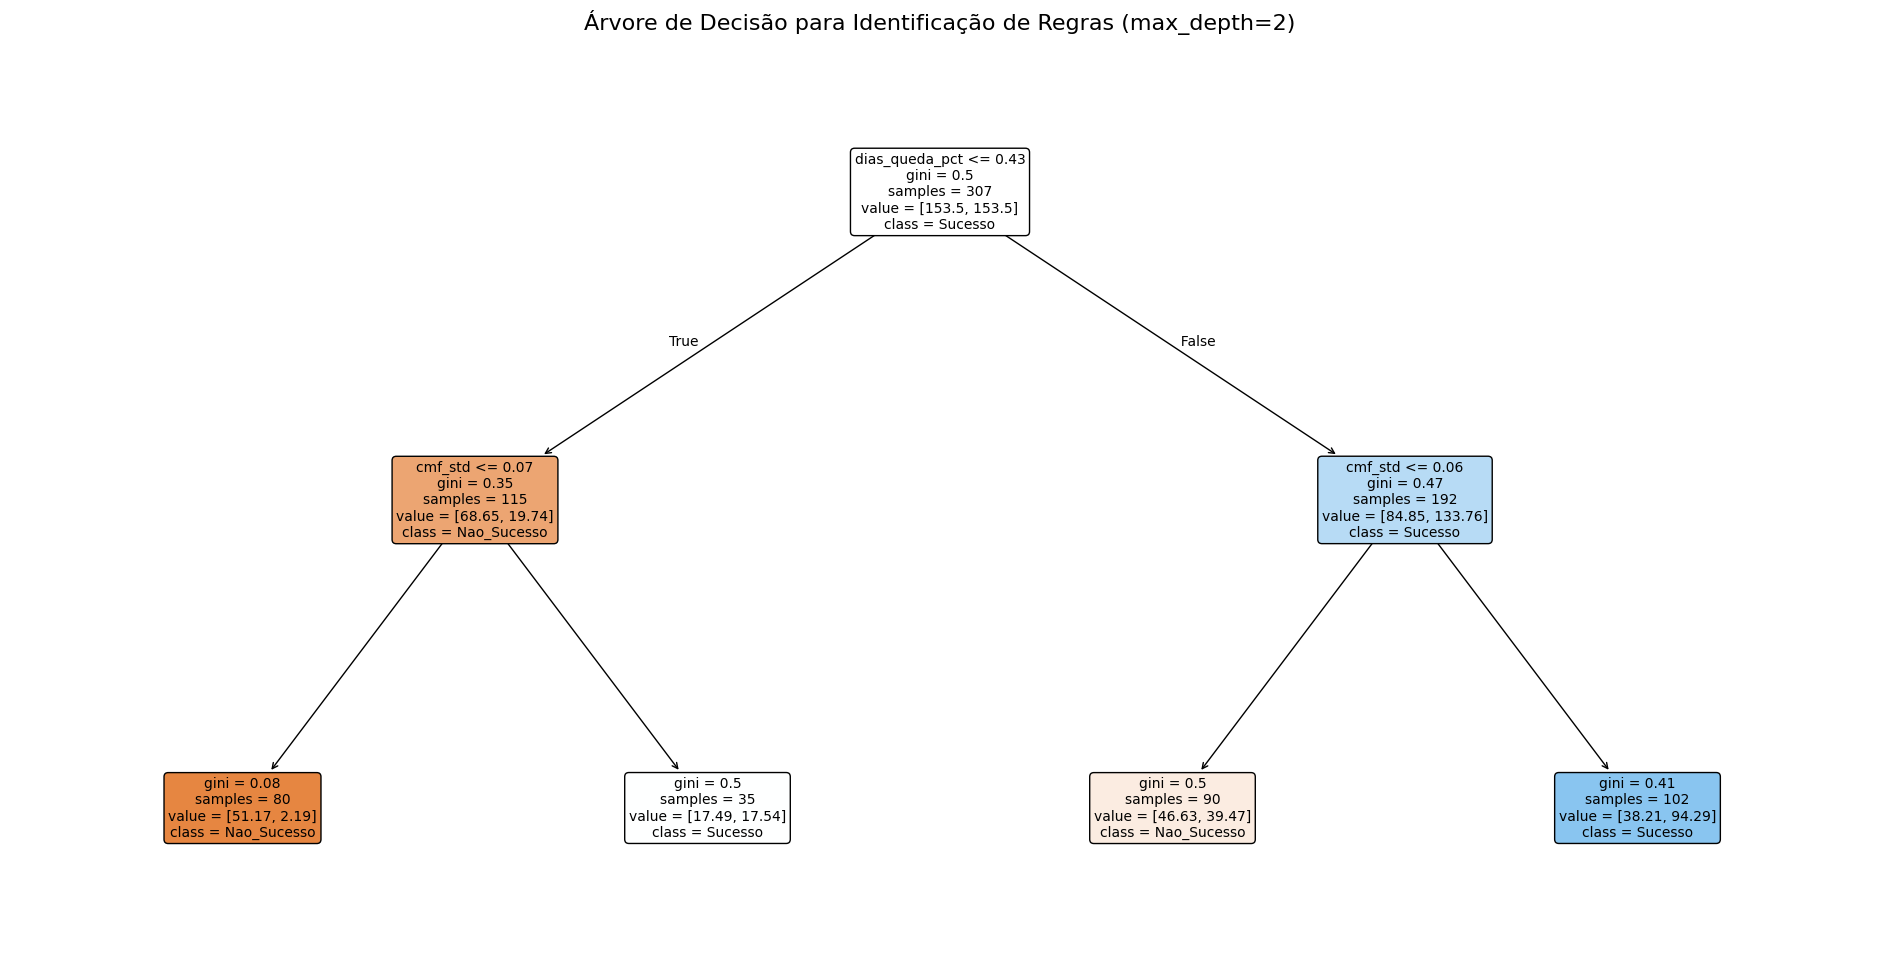

Folha 2: ['dias_queda_pct <= 0.4333', 'cmf_std <= 0.0722'] -> Classe 0: 76.7123287671233, Classe 1: 3.287671232876719, Total: 80
Folha 3: ['dias_queda_pct <= 0.4333', 'cmf_std > 0.0722'] -> Classe 0: 17.47226624405706, Classe 1: 17.527733755942954, Total: 35
Folha 5: ['dias_queda_pct > 0.4333', 'cmf_std <= 0.0592'] -> Classe 0: 48.74274661508703, Classe 1: 41.257253384913014, Total: 90
Folha 6: ['dias_queda_pct > 0.4333', 'cmf_std > 0.0592'] -> Classe 0: 29.415543607289962, Classe 1: 72.58445639271004, Total: 102

--- Regras Promissoras Encontradas ---
                                         regra  taxa_sucesso  num_sucessos  num_total_amostras
1   dias_queda_pct > 0.4333 E cmf_std > 0.0592      0.711612     72.584456                 102
0  dias_queda_pct <= 0.4333 E cmf_std > 0.0722      0.500792     17.527734                  35


In [93]:
# Chamar a função para encontrar as regras
regras_encontradas_df = encontrar_ilhas_com_arvore_decisao(
    X_treino=X_train,
    y_treino=y_train,
    max_profundidade=2,
    min_pureza_folha=0.50, # Buscar folhas com pelo menos 50% de sucesso
    min_amostras_folha=30   # E que tenham pelo menos 15 amostras
)

print("\n--- Regras Promissoras Encontradas ---")
if not regras_encontradas_df.empty:
    print(regras_encontradas_df.to_string())
else:
    print("Nenhuma regra encontrada.")

# Analise visual das combinações usadas

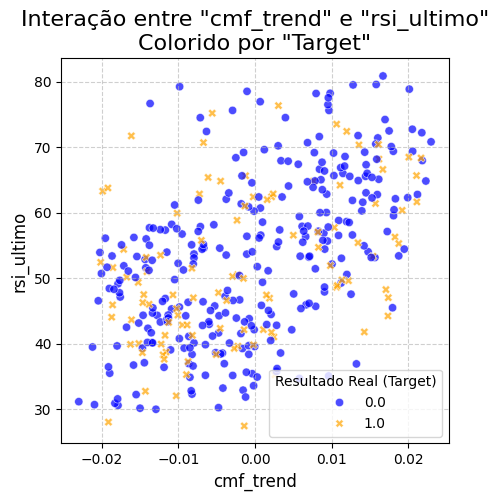

In [94]:
plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x='cmf_trend',
        feature_y='rsi_ultimo',
        target_col='Target'
    )


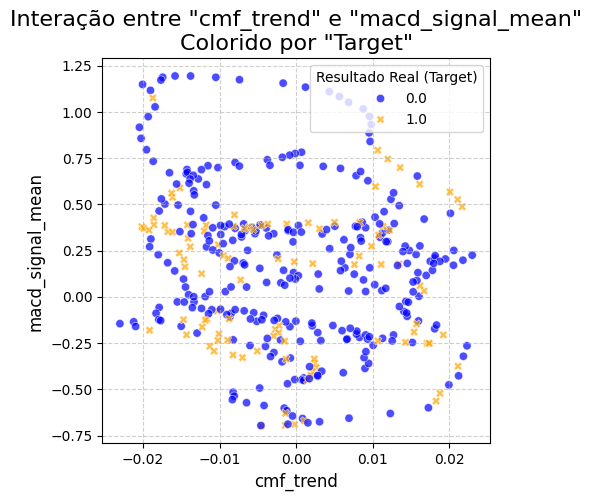

In [95]:
plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x='cmf_trend',
        feature_y='macd_signal_mean',
        target_col='Target'
    )

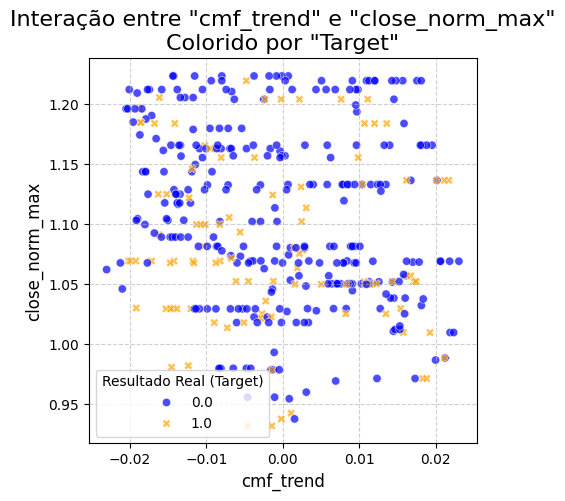

In [96]:
plotar_interacao_features(
        df_features_e_target=X.assign(Target=y),
        feature_x='cmf_trend',
        feature_y='close_norm_max',
        target_col='Target'
    )

## Criação de regras com base no decisiontree

In [97]:
# --- Regras Promissoras Encontradas ---
#                                                                                                             regra  taxa_sucesso  num_sucessos  num_total_amostras
# 0                          cmf_trend <= -0.0117 E bbands_largura_pct_trend <= 0.2313 E macd_signal_mean <= 0.4275      0.984348     18.702609                  19
# 1                                                                  cmf_trend > -0.0117 E close_norm_max <= 0.9792      0.854985     15.389728                  18
# 2  cmf_trend > -0.0117 E close_norm_max > 0.9792 E bbands_posicao_pct_ultimo <= 0.1996 E close_norm_std <= 0.0170      0.746702      7.467018                  11

In [98]:
# variáveis de interação
X['cmf_trend_x_bbands_largura_pct_trend'] = X['cmf_trend'] * X['bbands_largura_pct_trend']
X['cmf_trend_x_macd_signal_mean'] = X['cmf_trend'] * X['macd_signal_mean']
X['cmf_trend_x_close_norm_max'] = X['cmf_trend'] * X['close_norm_max']
X['cmf_trend_x_bbands_posicao_pct_ultimo'] = X['cmf_trend'] * X['bbands_posicao_pct_ultimo']

In [99]:
X['fundo_consolidacao'] = (X['cmf_trend'] <= -0.0117) & (X['bbands_largura_pct_trend'] <= 0.2313) & (X['macd_signal_mean'] <= 0.4275)
X['baixa_range'] = (X['cmf_trend'] > -0.0117) & (X['close_norm_max'] <= 0.9792)
X['pullback_fraco'] = (X['cmf_trend'] > -0.0117) & (X['close_norm_max'] > 0.9792) & (X['bbands_posicao_pct_ultimo'] <= 0.1996) & (X['close_norm_std'] <= 0.0170)

In [100]:
X.columns

Index(['close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
       'close_norm_trend', 'retorno_mean', 'retorno_std', 'dias_alta_pct',
       'dias_queda_pct', 'retorno_medio_pos', 'retorno_medio_neg',
       'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'correl_retorno_volume', 'rsi_mean', 'rsi_std', 'rsi_ultimo',
       'rsi_trend', 'macd_mean', 'macd_std', 'macd_ultimo', 'macd_trend',
       'macd_signal_mean', 'macd_signal_std', 'macd_signal_ultimo',
       'macd_signal_trend', 'macd_hist_mean', 'macd_hist_std',
       'macd_hist_ultimo', 'macd_hist_trend', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo',
       'atr_pct_trend', 'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
       'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
       'bbands_exau

In [101]:
colunas_X = ['fundo_consolidacao', 'baixa_range', 'pullback_fraco'
#             , 'close_norm_mean', 'close_norm_std', 'adc_close_norm_trend_BBAS3'
##             , 'dias_alta_pct', 'dias_queda_pct'
 #            ,'close_norm_vs_adc_norm_mean_geral'
             
             ]
X_reduzido = X[colunas_X].copy()
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X_reduzido, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
X_train.shape

(307, 3)

AUC no treino: 0.634
AUC na validação: 0.500
Diferença AUC (Treino - Validação): 0.134
PROVÁVEL OVERFITTING
PR AUC no treino: 0.401
PR AUC na validação: 0.260
Diferença PR AUC (Treino - Validação): 0.141
F1 Score no treino: 0.375
F1 Score na validação: 0.000


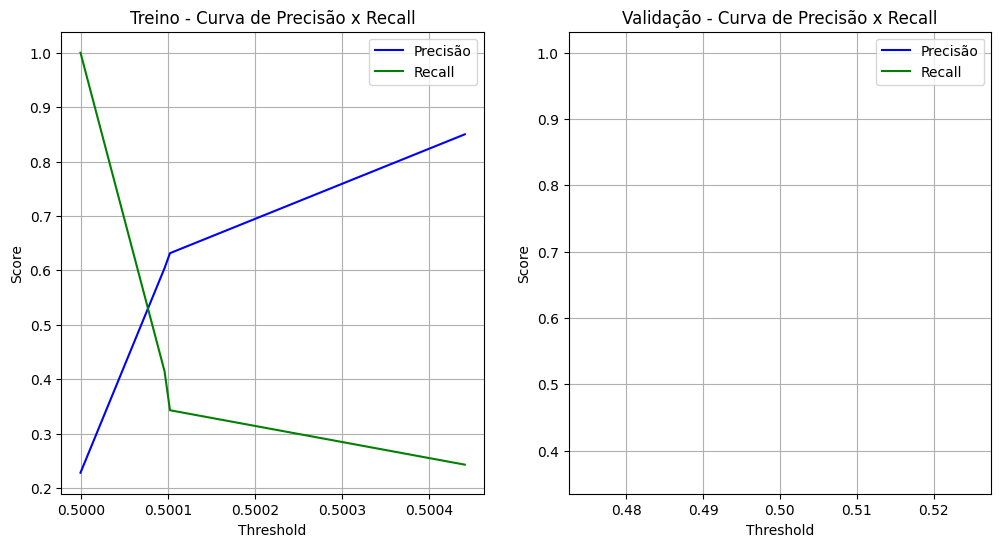

(np.float64(0.6338514979172113),
 np.float64(0.5),
 np.float64(0.1338514979172113),
 np.float64(0.4006922777274542),
 np.float64(0.25956284153005466),
 np.float64(0.37457292460642155),
 np.float64(0.0))

In [102]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.0001, penalty='l2')
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

# Testar grupos de variáveis incrementalmente

In [54]:
X, y = pp.preparar_X_y_agregado(df, dias_entrada=dias_entrada, dropna=True, tipo_drop_na='linhas', papel=papel)
X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_validacao_scaled = pd.DataFrame(scaler.transform(X_validacao), columns=X_validacao.columns, index=X_validacao.index)

c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:791: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:791: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:791: RuntimeWarning: Mean of empty slice
  linha['adc_close_norm_mean_geral_ultimo'] = np.nanmean(lista_close_norm_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:791: Runtim

INFO: 199 linha(s) removidas de X e y devido a NaNs.


In [13]:
# Mapeamento de grupos de features
GRUPOS_DE_FEATURES = {
    # Grupo 1: O mais básico. Como o preço se moveu?
    'preco_norm': [
        'close_norm_mean', 'close_norm_std', 'close_norm_max', 'close_norm_min',
        'close_norm_trend', 'retorno_acumulado_norm'
    ],
    # Grupo 2: Dinâmica dos retornos diários
    'retornos': [
        'retorno_mean', 'retorno_std', 'dias_alta_pct', 'dias_queda_pct',
        'retorno_medio_pos', 'retorno_medio_neg'
    ],
    # Grupo 3: Volume básico
    'volume': [
        'volume_mean', 'volume_std', 'volume_trend', 'volume_ult_vs_mean',
        'correl_retorno_volume'
    ],
    # Grupo 4: Momentum clássico (RSI, MACD)
    'momentum': [
        'rsi_mean', 'rsi_std', 'rsi_ultimo', 'rsi_trend',
        'macd_hist_mean', 'macd_hist_std', 'macd_hist_ultimo', 'macd_hist_trend'
        # Omitindo macd e macd_signal puros para reduzir redundância com macd_hist
    ],
    # Grupo 5: Volume-Preço (sinal mais sofisticado)
    'volume_preco': [
        'obv_mean', 'obv_std', 'obv_ultimo', 'obv_trend',
        'cmf_mean', 'cmf_std', 'cmf_ultimo', 'cmf_trend',
        'mfi_mean', 'mfi_std', 'mfi_ultimo', 'mfi_trend' # Adicionado MFI aqui
    ],
    # Grupo 6: Regime de Mercado (Tendência e Volatilidade)
    'regime_mercado': [
        'atr_pct_mean', 'atr_pct_std', 'atr_pct_ultimo', 'atr_pct_trend',
        'adx_ultimo', 'adx_trend', 'tendencia_forte_adx25',
        'bbands_largura_pct_ultimo', 'bbands_largura_pct_trend',
        'bbands_posicao_pct_ultimo', 'bbands_exaustao_compra',
        'bbands_exaustao_venda'
    ],
    # Grupo 7: Relação com o Mercado (IBOV)
    'mercado_geral': [
        'ibov_trend', 'ibov_std', 'retorno_desde_mudanca_ibov', 'ibov_amplitude',
        'correl_papel_ibov', 'beta_papel_ibov', 'alpha_papel_vs_ibov_mean'
    ],
    # Grupo 8: Relação com Pares (Adicionais)
    'pares_setor': [
        'adc_close_norm_trend_BBAS3', 'adc_correl_com_principal_BBAS3', 'adc_adx_ultimo_BBAS3',
        'adc_close_norm_trend_BBDC4', 'adc_correl_com_principal_BBDC4', 'adc_adx_ultimo_BBDC4',
        'adc_close_norm_trend_SANB11', 'adc_correl_com_principal_SANB11', 'adc_adx_ultimo_SANB11',
        'adc_close_norm_mean_geral_ultimo', 'close_norm_vs_adc_norm_mean_geral'
        # Adicione outras features de 'adc_' aqui se tiver
    ],
    # Grupo 9: Fatores Macro (Juros, Inflação, Câmbio)
    'macro': [
        'selic_ultimo', 'selic_comparacao_anterior', 'selic_dias_desde_mudanca',
        'ipca_ultimo', 'ipca_comparacao_anterior', 'ipca_dias_desde_mudanca',
        'dolar_ultimo', 'dolar_trend', 'dolar_std', 'retorno_desde_mudanca_dolar'
    ],
    # Grupo 10: Features Temporais/Especiais
    'temporais': [
        'dia_semana_0', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4',
        'feriado', 'proximo_dia_util'
    ],
    # Grupo 11: Features de Interação (as que a árvore encontrou)
    'interacoes_manuais': [
        'cmf_trend_x_bbands_largura_pct_trend', 'cmf_trend_x_macd_signal_mean',
        'cmf_trend_x_close_norm_max', 'cmf_trend_x_bbands_posicao_pct_ultimo'
    ]
}

In [14]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.base import clone # Para criar novas instâncias do modelo

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit # <<< A estrela da função

def avaliar_estrategia_com_timeseriessplit(
        modelo_template, # Um modelo NÃO treinado
        X_super_treino: pd.DataFrame,
        y_super_treino: pd.Series,
        n_splits: int = 5 # <<< Novo parâmetro principal: número de folds
    ):
    """
    Avalia uma estratégia de modelagem usando TimeSeriesSplit do scikit-learn
    DENTRO do conjunto de "super treino". O modelo é retreinado em cada split.

    Args:
        modelo_template: Uma instância NÃO TREINADA do modelo a ser avaliado.
        X_super_treino: O conjunto completo de features de treino.
        y_super_treino: Os alvos completos de treino.
        n_splits (int): O número de splits (folds) a serem criados.

    Returns:
        dict: Dicionário com as métricas médias (f1_medio, precisao_media, recall_medio).
    """
    print(f"\n--- Avaliando Estratégia com TimeSeriesSplit (n_splits={n_splits}) ---")

    # TimeSeriesSplit cria janelas de treino que se expandem.
    # Ex: para n_splits=5:
    # Fold 1: treina em [bloco 1], testa em [bloco 2]
    # Fold 2: treina em [bloco 1, bloco 2], testa em [bloco 3]
    # Fold 3: treina em [bloco 1, bloco 2, bloco 3], testa em [bloco 4]
    # ... e assim por diante.
    tscv = TimeSeriesSplit(n_splits=n_splits)

    f1s, precisions, recalls = [], [], []

    # O loop agora itera sobre os splits gerados pelo tscv
    for fold, (train_index, test_index) in enumerate(tscv.split(X_super_treino)):
        X_treino_fold = X_super_treino.iloc[train_index]
        y_treino_fold = y_super_treino.iloc[train_index]
        #validar sobre próximos 30 dias        
        X_teste_fold = X_super_treino.iloc[test_index[:30]]
        y_teste_fold = y_super_treino.iloc[test_index[:30]]

        print(f"Fold {fold + 1}/{n_splits}: Treinando com {len(X_treino_fold)} amostras, Validando com {len(X_teste_fold)} amostras.")

        # Retreinar o modelo em cada fold de treino
        modelo_fold = clone(modelo_template)
        try:
            modelo_fold.fit(X_treino_fold.values, y_treino_fold.values) # Usando .values por consistência
        except Exception as e:
            print(f"  ERRO no fit do Fold {fold + 1}: {e}. Pulando este fold.")
            continue

        # Fazer previsões (threshold padrão de 0.5)
        y_pred_fold = modelo_fold.predict(X_teste_fold.values)

        # Calcular e armazenar métricas
        f1s.append(f1_score(y_teste_fold, y_pred_fold, zero_division=0))
        precisions.append(precision_score(y_teste_fold, y_pred_fold, zero_division=0))
        recalls.append(recall_score(y_teste_fold, y_pred_fold, zero_division=0))

    if not f1s: # Se nenhuma janela foi processada com sucesso
        print("AVISO: Nenhuma métrica foi calculada. Verifique os dados e os splits.")
        return {'f1_medio': 0, 'precisao_media': 0, 'recall_medio': 0}

    # Calcular as médias das métricas de todos os folds
    resultado = {
        'f1_medio': np.mean(f1s),
        'f1_std': np.std(f1s),
        'precisao_media': np.mean(precisions),
        'recall_medio': np.mean(recalls)
    }

    print(f"Resultado Médio dos {len(f1s)} Folds: F1={resultado['f1_medio']:.3f}, Precisão={resultado['precisao_media']:.3f}, Recall={resultado['recall_medio']:.3f}")
    return resultado

In [15]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Assumimos que a função 'avaliar_estrategia_com_timeseriessplit' já está definida
# e que X_super_treino e y_super_treino estão disponíveis.

def avaliar_performance_incremental_de_features(
        X_treino_completo, y_treino,
        grupos_de_features,
        ordem_dos_grupos, # Lista com os nomes dos grupos na ordem a serem adicionados
        modelo_template,
        n_splits_cv=5
    ):
    """
    Avalia a performance de um modelo adicionando grupos de features incrementalmente,
    usando validação cruzada temporal (TimeSeriesSplit).

    Args:
        X_treino_completo: DataFrame com TODAS as features.
        y_treino: Série com os alvos.
        grupos_de_features (dict): Dicionário mapeando nome do grupo para lista de features.
        ordem_dos_grupos (list): Ordem em que os grupos serão adicionados.
        modelo_template: Modelo não treinado a ser usado.
        n_splits_cv (int): Número de folds para a validação cruzada.

    Returns:
        pd.DataFrame: Um DataFrame com os resultados de performance para cada etapa incremental.
    """
    print("\n--- Iniciando Avaliação Incremental de Grupos de Features ---")
    
    resultados_incrementais = []
    features_usadas_acumuladas = []

    for nome_grupo in ordem_dos_grupos:
        print(f"\n>>> Adicionando grupo de features: '{nome_grupo}'")
        
        # Adiciona as features do novo grupo às features acumuladas
        features_novas_do_grupo = grupos_de_features.get(nome_grupo, [])
        # Filtrar para garantir que apenas colunas existentes em X_treino_completo sejam adicionadas
        features_novas_do_grupo = [f for f in features_novas_do_grupo if f in X_treino_completo.columns]
        
        if not features_novas_do_grupo:
            print(f"  Aviso: Nenhuma feature encontrada para o grupo '{nome_grupo}' no DataFrame. Pulando.")
            continue
            
        features_usadas_acumuladas.extend(features_novas_do_grupo)
        # Remover duplicatas caso haja alguma sobreposição (improvável com boa organização)
        features_usadas_acumuladas = sorted(list(set(features_usadas_acumuladas)))
        
        print(f"  Total de features agora: {len(features_usadas_acumuladas)}")

        # Selecionar o subconjunto de dados para este teste
        X_subset = X_treino_completo[features_usadas_acumuladas]

        # Avaliar o modelo com o conjunto de features atual
        metricas_grupo = avaliar_estrategia_com_timeseriessplit(
            modelo_template=modelo_template,
            X_super_treino=X_subset,
            y_super_treino=y_treino,
            n_splits=n_splits_cv
        )

        resultados_incrementais.append({
            'grupo_adicionado': nome_grupo,
            'num_features': len(features_usadas_acumuladas),
            'f1_medio': metricas_grupo['f1_medio'],
            'precisao_media': metricas_grupo['precisao_media'],
            'recall_medio': metricas_grupo['recall_medio']
        })

    return pd.DataFrame(resultados_incrementais)

In [16]:
ordem_de_teste_funcional = [
    'preco_norm',
    'retornos',
    'volume',
    'momentum',
    'volume_preco',
    'regime_mercado',
    'mercado_geral',
    'pares_setor',
    'macro',
    'temporais',
    'interacoes_manuais'
]

# 2. Definir o modelo que será testado
modelo_logreg_template = LogisticRegression(solver='liblinear', penalty='l2', C=0.01, random_state=42, class_weight='balanced')

# 3. Executar a avaliação incremental
df_performance_incremental = avaliar_performance_incremental_de_features(
    X_train_scaled, y_train,
    GRUPOS_DE_FEATURES,
    ordem_de_teste_funcional,
    modelo_logreg_template,
    n_splits_cv=5
)

print("\n--- Resultado da Avaliação Incremental de Features ---")
print(df_performance_incremental.round(3).to_string())


--- Iniciando Avaliação Incremental de Grupos de Features ---

>>> Adicionando grupo de features: 'preco_norm'
  Total de features agora: 6

--- Avaliando Estratégia com TimeSeriesSplit (n_splits=5) ---
Fold 1/5: Treinando com 53 amostras, Validando com 30 amostras.
Fold 2/5: Treinando com 104 amostras, Validando com 30 amostras.
Fold 3/5: Treinando com 155 amostras, Validando com 30 amostras.
Fold 4/5: Treinando com 206 amostras, Validando com 30 amostras.
Fold 5/5: Treinando com 257 amostras, Validando com 30 amostras.
Resultado Médio dos 5 Folds: F1=0.299, Precisão=0.207, Recall=0.690

>>> Adicionando grupo de features: 'retornos'
  Total de features agora: 12

--- Avaliando Estratégia com TimeSeriesSplit (n_splits=5) ---
Fold 1/5: Treinando com 53 amostras, Validando com 30 amostras.
Fold 2/5: Treinando com 104 amostras, Validando com 30 amostras.
Fold 3/5: Treinando com 155 amostras, Validando com 30 amostras.
Fold 4/5: Treinando com 206 amostras, Validando com 30 amostras.
Fold 

In [60]:
# vamos testar com preco_norm e retornos
grupos_desejados = ['preco_norm', 'retornos']

features = []
for grupo in grupos_desejados:
    if grupo in GRUPOS_DE_FEATURES:
        features.extend(GRUPOS_DE_FEATURES[grupo])
    else:
        print(f"Aviso: Grupo '{grupo}' não encontrado em GRUPOS_DE_FEATURES.")
              

features = [f for f in features if f in X_train_scaled.columns]              
# Selecionar o subconjunto de dados para este teste
X_train_subset = X_train_scaled[features]
X_validacao_subset = X_validacao_scaled[features]

In [32]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, precisao_minima_para_otimizacao=0.4)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.4681
Melhores Parâmetros Encontrados:
{'C': np.float64(0.0001), 'penalty': 'l2', 'solver': 'saga'}


LogisticRegression(C=np.float64(0.0001), class_weight='balanced', max_iter=5000,
                   random_state=42, solver='saga')

AUC no treino: 0.756
AUC na validação: 0.566
Diferença AUC (Treino - Validação): 0.190
PROVÁVEL OVERFITTING
PR AUC no treino: 0.534
PR AUC na validação: 0.357
Diferença PR AUC (Treino - Validação): 0.177
F1 Score no treino: 0.381
F1 Score na validação: 0.190


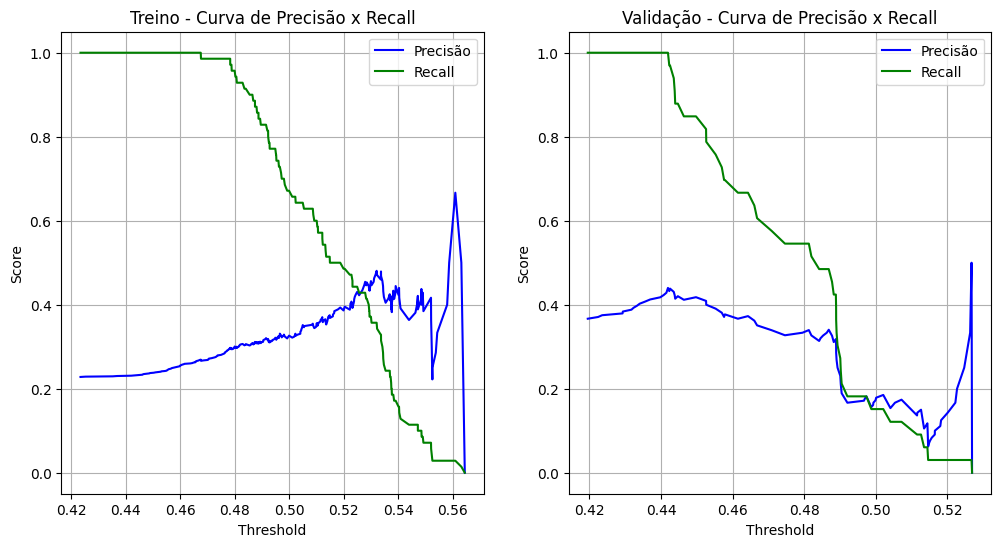

(np.float64(0.755831304565381),
 np.float64(0.5655202522920253),
 np.float64(0.19031105227335565),
 np.float64(0.5342984491463092),
 np.float64(0.3571877099326652),
 np.float64(0.380861056768544),
 np.float64(0.18976352207960287))

In [38]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.001, penalty='l2')
modelo_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 85f62e5adc334566ba4fa27abc32c72c para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.713
AUC na validação: 0.437

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.52
  Precisão Média Esperada: 39.22%
  Recall Médio Esperado: 50.21%
  Janelas Usadas para Precisão: 239.0

Threshold ideal baseado em mínimo recall ou precisão: 0.52

--- Conjunto de Validação --- Janelas
Precisão média (em 47 janelas com previsão positiva): 0.143
Recall médio: 0.124
Sinais de compra presentes na vallidação: 33.0
Sinais de compra previstos na validação: 7
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run 85f62e5adc334566ba4fa27abc32c72c


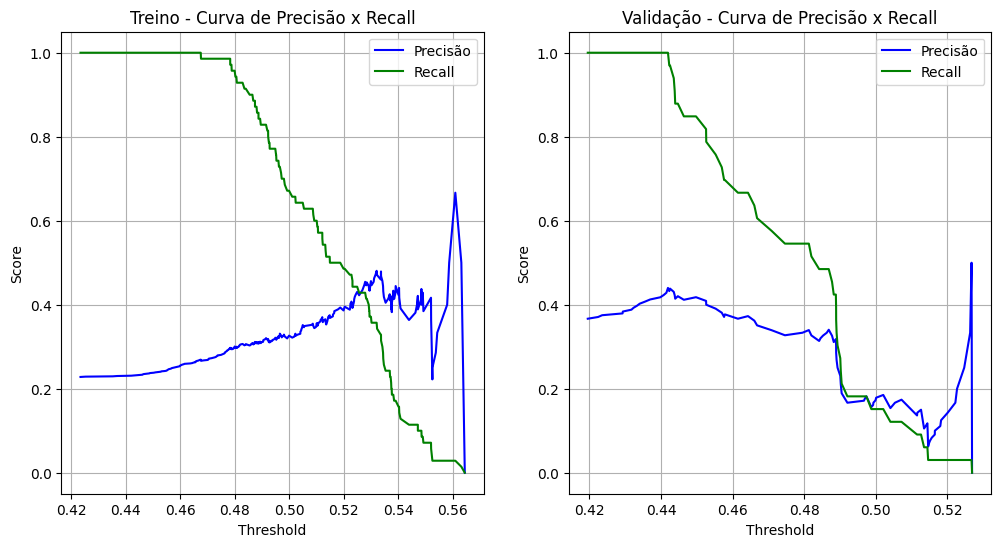

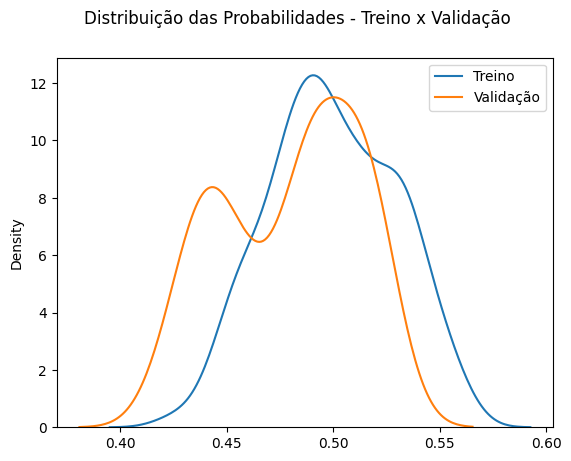

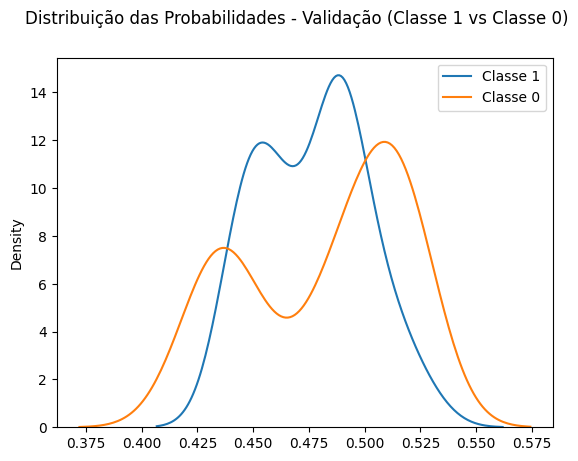

In [42]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.52
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

Conclusão: este modelo não generalizou bem nas janelas deslizantes

## Tentativa com LGBM

Dividindo Super Treino (307 amostras):
  - Treino Base LGBM: 246 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 61 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[54]	valid_0's auc: 0.733204	valid_0's binary_logloss: 0.652969
Treinamento LGBM concluído. Melhor iteração: 54

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (61 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.779
AUC na validação: 0.507
Diferença AUC (Treino - Validação): 0.271
PROVÁVEL OVERFITTING
PR AUC no treino: 0.493
PR AUC na validação: 0.262
Diferença PR AUC (Treino - Validação): 0.230
F1 Score no treino: 0.483
F1 Score na validação: 0.133


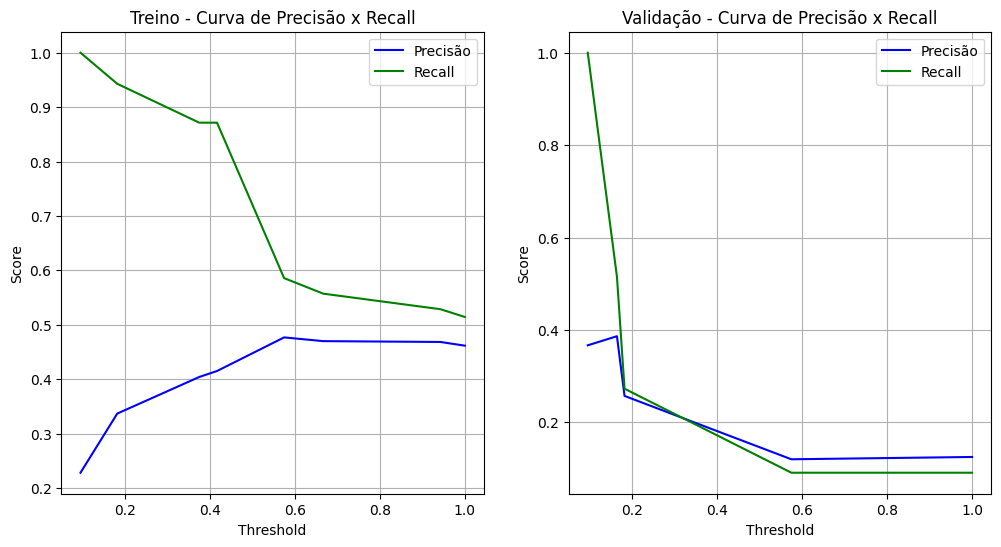

(np.float64(0.7785942175277619),
 np.float64(0.5074454477488018),
 np.float64(0.2711487697789601),
 np.float64(0.49269857574111364),
 np.float64(0.26233925458800567),
 np.float64(0.48265545899960727),
 np.float64(0.13292131429118))

In [63]:
import treinamento_lgbm  as tl

# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.
lgbm_params = {
    'n_estimators': 1000,
    'learning_rate': 0.01,          # Pode ser um pouco mais alto, pois o modelo é muito restrito

    # --- Regularização da Árvore (Agressiva) ---
    'num_leaves': 8,                # BEM REDUZIDO: Árvores muito simples.
    'max_depth': 4,                 # BEM REDUZIDO: Árvores muito rasas.
    'min_child_samples': 50,        # BEM AUMENTADO: Exige muitos dados por folha.
    'min_gain_to_split': 0.1,       # AUMENTADO: A penalidade para split é maior.

    # --- Regularização por Amostragem e Penalidade (Agressiva) ---
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'reg_alpha': 1.0,               # AUMENTADO: Penalidade L1 mais forte.
    'reg_lambda': 1.0,              # AUMENTADO: Penalidade L2 mais forte.
    
    # --- Outros Parâmetros ---
    'random_state': 42,
    'n_jobs': -1,
    'class_weight': class_weight,
    'importance_type': 'gain',
    'verbosity': -1
}


# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = tl.criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_subset, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    lgbm_params=lgbm_params,
    eval_metric_lgbm='auc',
    estrategia_calibracao_cv='prefit',
    class_weight='balanced'#{0:1, 1:4} # Ajuste conforme necessário
)

tr.comparar_auc_conjuntos(modelo_treinado, X_train_subset, y_train, X_validacao_subset, y_validacao)

# Teste hipersimplificado

In [27]:
features = ['close_norm_ultimo', 'retorno_acumulado_ultimos_5_dias', 'atr_pct_ultimo', 'alpha_papel_vs_ibov_mean', 'cmf_ultimo']

X_train_subset = X_train[features]
X_validacao_subset = X_validacao[features]

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Criar um pipeline com o scaler e o modelo
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Normalização
    ('modelo', LogisticRegression(solver='liblinear', max_iter=5000, random_state=42))
])

In [29]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits


ValueError: 
All the 150 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\base.py", line 1389,

AUC no treino: 0.000
AUC na validação: 0.711
Diferença AUC (Treino - Validação): -0.711
PR AUC no treino: 0.000
PR AUC na validação: 0.516
Diferença PR AUC (Treino - Validação): -0.516
F1 Score no treino: 0.000
F1 Score na validação: 0.056


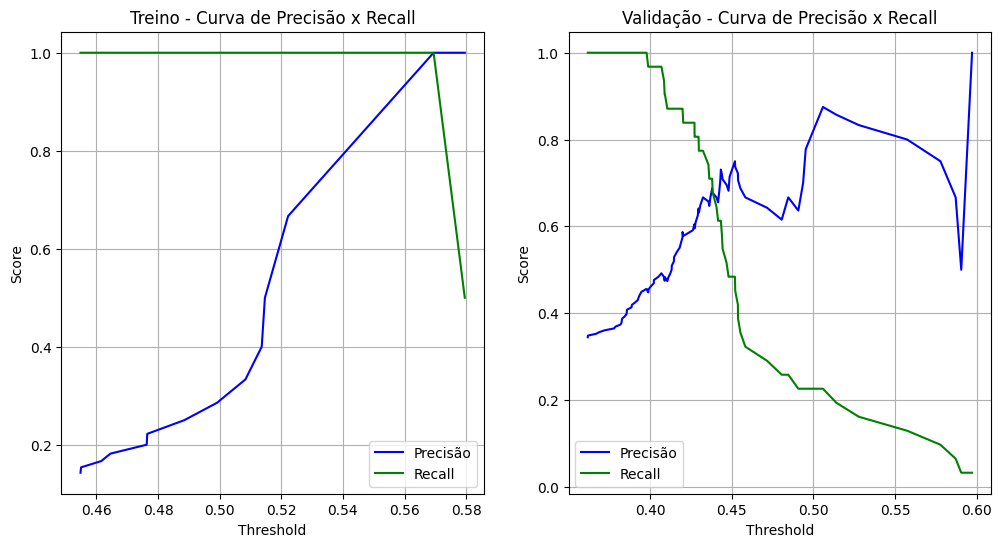

(0,
 np.float64(0.7114086835680309),
 np.float64(-0.7114086835680309),
 0,
 np.float64(0.5164939159061425),
 0,
 np.float64(0.05572162414286434))

In [34]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.01, penalty='l2')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()),  # Normalização
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: b648ab2e1dfb44c0b0bf3d9788d051b4 para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.597
AUC na validação: 0.669

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.49
  Precisão Média Esperada: 22.52%
  Recall Médio Esperado: 100.00%
  Janelas Usadas para Precisão: 278.0

Threshold ideal baseado em mínimo recall ou precisão: 0.49

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.237
Recall médio: 1.000
Sinais de compra presentes na vallidação: 31.0
Sinais de compra previstos na validação: 90
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run b648ab2e1dfb44c0b0bf3d9788d051b4


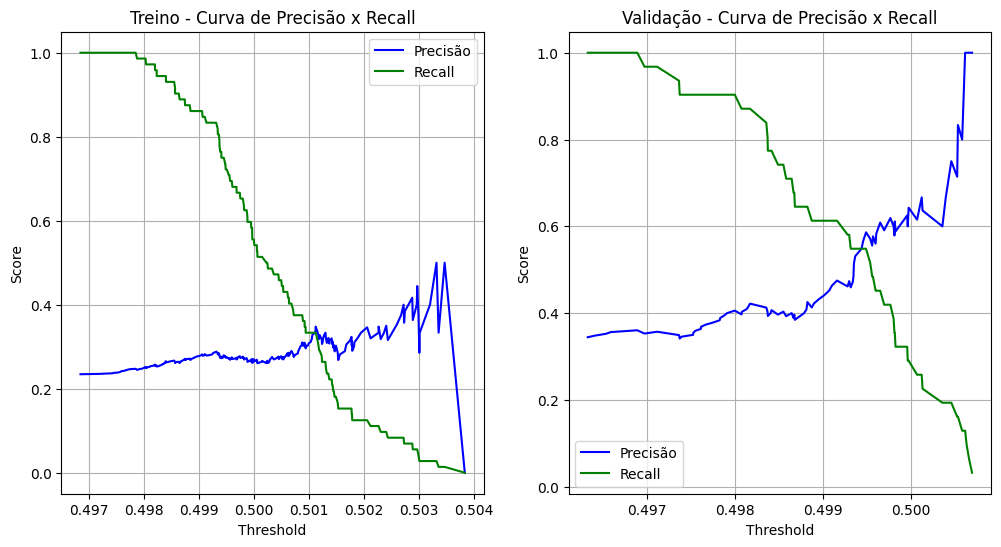

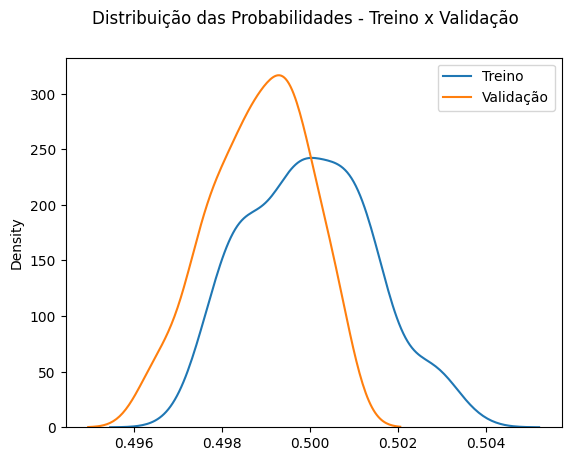

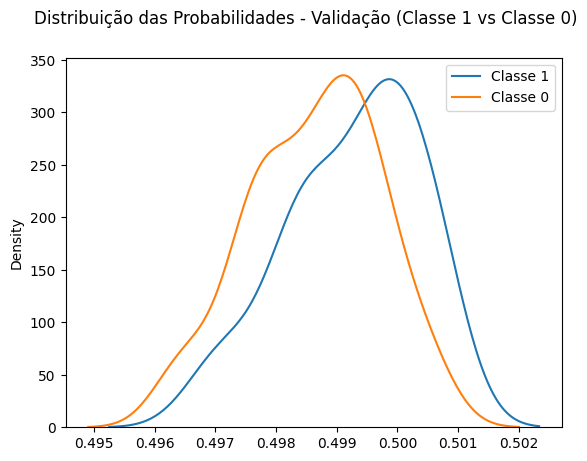

In [20]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.49
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

In [31]:
pd.DataFrame({'feature': X_train_subset.columns
              , 'coef': modelo_rl.coef_[0]
              , 'coef_abs': np.abs(modelo_rl.coef_[0])              
              }).sort_values(by='coef_abs', ascending=False).head(20)

,feature,coef,coef_abs
2,atr_pct_ultimo,0.000883,0.000883
0,close_norm_ultimo,-0.000634,0.000634
4,cmf_ultimo,0.000370,0.000370
3,alpha_papel_vs_ibov_mean,-0.000339,0.000339
1,retorno_acumulado_ultimos_5_dias,-0.000127,0.000127


# Tentatvia com grupos TRANSVERSAIS

In [43]:
# --- 1. Defina seus NOVOS Grupos de Features Transversais ---

GRUPOS_TRANSVERSAIS_DE_FEATURES = {
    # Grupo 1: FOTO ATUAL DO MERCADO (indicadores principais)
    'principais_estado_atual': [
        'close_norm_mean', # Nível de preço relativo na janela
        'retorno_mean',    # Direção média recente
        'volume_mean',     # Atividade média
        'rsi_ultimo',      # Momentum atual
        'mfi_ultimo',      # Fluxo de dinheiro atual
        'adx_ultimo',      # Força da tendência atual
        'bbands_posicao_pct_ultimo', # Posição relativa na volatilidade
        'atr_pct_ultimo',  # Magnitude da volatilidade atual
        'correl_papel_ibov', # Relação com o mercado
        'alpha_papel_vs_ibov_mean', # Desempenho relativo ao mercado
        'adc_close_norm_mean_geral_ultimo' # Nível relativo dos pares
    ],
    # Grupo 2: A DINÂMICA RECENTE (tendências e volatilidades)
    'secundarias_dinamica': [
        'close_norm_trend',
        'retorno_std',
        'volume_trend',
        'volume_std',
        'rsi_trend',
        'cmf_trend',
        'adx_trend',
        'bbands_largura_pct_trend'
        # Adicione outros '_std' e '_trend' aqui
    ],
    # Grupo 3: CONTEXTO MACRO E TEMPORAL
    'terciarias_contexto': [
        'selic_ultimo', 'selic_comparacao_anterior', 'selic_dias_desde_mudanca',
        'ipca_ultimo', 'ipca_comparacao_anterior', 'ipca_dias_desde_mudanca',
        'dolar_trend', 'dolar_std',
        'dia_semana_0', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4'
    ],
    # Grupo 4: INTERAÇÕES (adicionar por último)
    'quaternarias_interacoes': [
        'tendencia_forte_adx25', # Interação implícita de ADX
        'bbands_exaustao_compra', # Interação implícita de BBP
        'bbands_exaustao_venda',
        'cmf_trend_x_bbands_largura_pct_trend', # Interação explícita
        'cmf_trend_x_macd_signal_mean',
        # Adicione suas outras features de regra da árvore de decisão aqui
    ]
    # Adicione mais grupos conforme sua classificação
}

# --- 2. Defina a Ordem de Teste ---
ordem_de_teste_transversal = [
    'principais_estado_atual',
    'secundarias_dinamica',
    'terciarias_contexto',
    'quaternarias_interacoes'
]

In [46]:
# 2. Definir o modelo que será testado
modelo_logreg_template = LogisticRegression(solver='liblinear', penalty='l2', C=0.01, random_state=42, class_weight='balanced')

# 3. Executar a avaliação incremental
df_performance_incremental = avaliar_performance_incremental_de_features(
    X_train_scaled, y_train,
    GRUPOS_TRANSVERSAIS_DE_FEATURES,
    ordem_de_teste_transversal,
    modelo_logreg_template,
    n_splits_cv=5
)

print("\n--- Resultado da Avaliação Incremental de Features ---")
print(df_performance_incremental.round(3).to_string())


--- Iniciando Avaliação Incremental de Grupos de Features ---

>>> Adicionando grupo de features: 'principais_estado_atual'
  Total de features agora: 10

--- Avaliando Estratégia com TimeSeriesSplit (n_splits=5) ---
Fold 1/5: Treinando com 52 amostras, Validando com 30 amostras.
Fold 2/5: Treinando com 103 amostras, Validando com 30 amostras.
Fold 3/5: Treinando com 154 amostras, Validando com 30 amostras.
Fold 4/5: Treinando com 205 amostras, Validando com 30 amostras.
Fold 5/5: Treinando com 256 amostras, Validando com 30 amostras.
Resultado Médio dos 5 Folds: F1=0.314, Precisão=0.213, Recall=0.658

>>> Adicionando grupo de features: 'secundarias_dinamica'
  Total de features agora: 18

--- Avaliando Estratégia com TimeSeriesSplit (n_splits=5) ---
Fold 1/5: Treinando com 52 amostras, Validando com 30 amostras.
Fold 2/5: Treinando com 103 amostras, Validando com 30 amostras.
Fold 3/5: Treinando com 154 amostras, Validando com 30 amostras.
Fold 4/5: Treinando com 205 amostras, Valida

In [48]:
# vamos testar com preco_norm e retornos
grupos_desejados = ['principais_estado_atual', 'secundarias_dinamica', 'terciarias_contexto']

features = []
for grupo in grupos_desejados:
    if grupo in GRUPOS_TRANSVERSAIS_DE_FEATURES:
        features.extend(GRUPOS_TRANSVERSAIS_DE_FEATURES[grupo])
    else:
        print(f"Aviso: Grupo '{grupo}' não encontrado em GRUPOS_DE_FEATURES.")
              

features = [f for f in features if f in X_train_scaled.columns]              
# Selecionar o subconjunto de dados para este teste
X_train_subset = X_train_scaled[features]
X_validacao_subset = X_validacao_scaled[features]

In [49]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, precisao_minima_para_otimizacao=0.4)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.3099
Melhores Parâmetros Encontrados:
{'C': np.float64(0.0001), 'penalty': 'l1', 'solver': 'saga'}


LogisticRegression(C=np.float64(0.0001), class_weight='balanced', max_iter=5000,
                   penalty='l1', random_state=42, solver='saga')

AUC no treino: 0.661
AUC na validação: 0.561
Diferença AUC (Treino - Validação): 0.100
PROVÁVEL OVERFITTING
PR AUC no treino: 0.451
PR AUC na validação: 0.344
Diferença PR AUC (Treino - Validação): 0.107
F1 Score no treino: 0.433
F1 Score na validação: 0.249


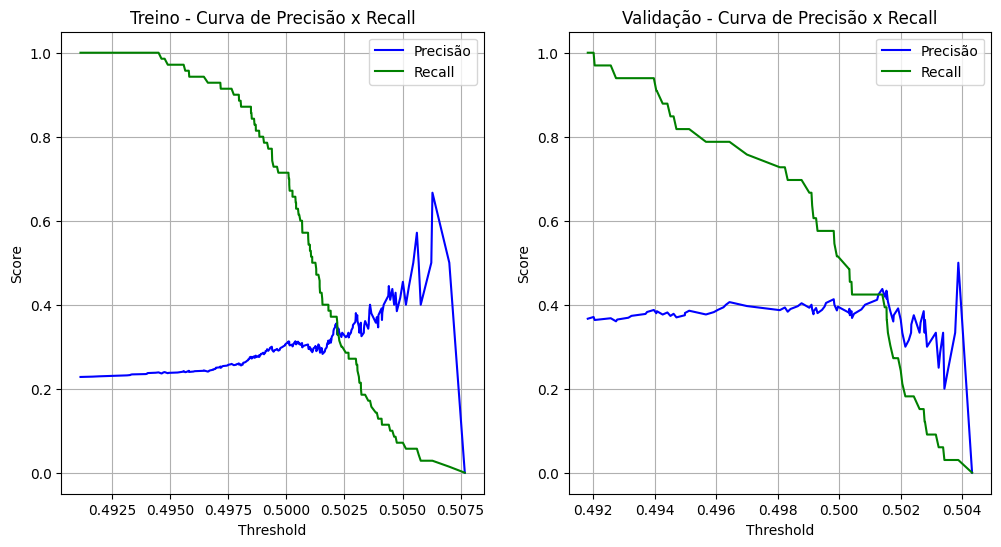

(np.float64(0.661164476157839),
 np.float64(0.5608008053799668),
 np.float64(0.10036367077787223),
 np.float64(0.4505492006446708),
 np.float64(0.3435017075093415),
 np.float64(0.43271675435259555),
 np.float64(0.2494208717276442))

In [54]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='liblinear', max_iter=5000,random_state=42, class_weight=class_weight, C=0.0001, penalty='l2')
modelo_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 0a0978551f0a4733a1f6d423fa5e278a para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.634
AUC na validação: 0.533

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.49
  Precisão Média Esperada: 24.42%
  Recall Médio Esperado: 98.18%
  Janelas Usadas para Precisão: 278.0

Threshold ideal baseado em mínimo recall ou precisão: 0.49

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.271
Recall médio: 0.740
Sinais de compra presentes na vallidação: 33.0
Sinais de compra previstos na validação: 70
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run 0a0978551f0a4733a1f6d423fa5e278a


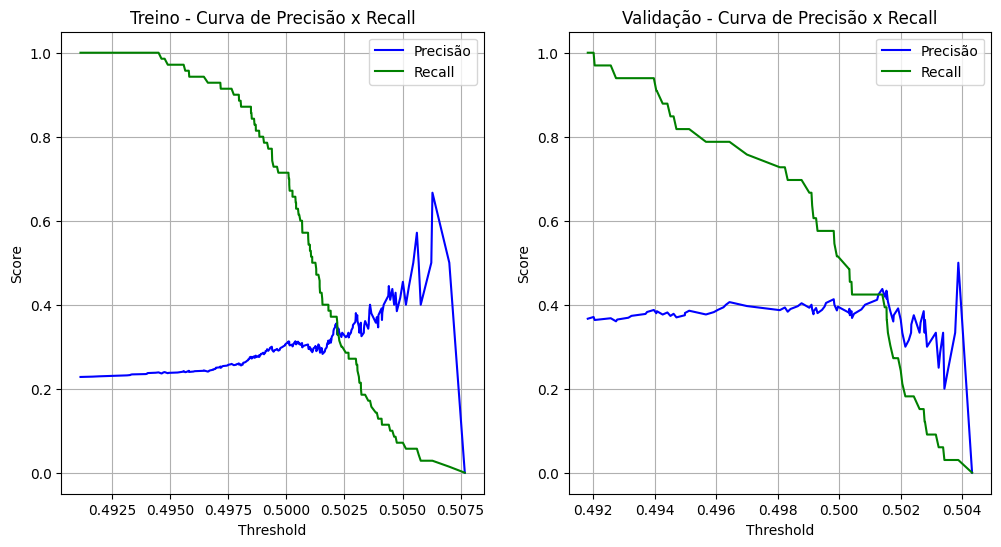

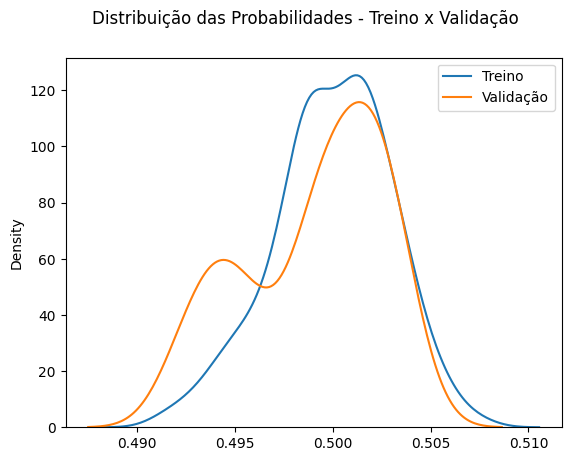

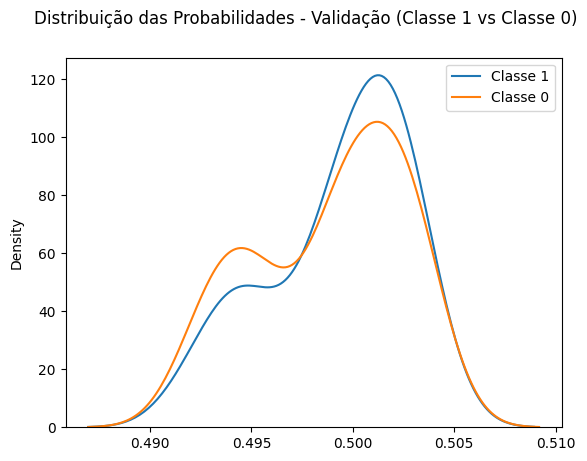

In [58]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.495
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Tentativa de identificar features por informação mútua

In [55]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

def ranquear_features_por_info_mutua(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """
    Calcula a Informação Mútua entre cada feature em X e o alvo y,
    e retorna um DataFrame com as features ranqueadas.

    Args:
        X (pd.DataFrame): DataFrame de features.
        y (pd.Series): Série com os alvos.

    Returns:
        pd.DataFrame: DataFrame com as colunas 'feature' e 'mutual_info_score',
                      ordenado do maior para o menor score.
    """
    print("\n--- Calculando Informação Mútua para todas as features... ---")
    # A Informação Mútua funciona melhor com dados discretos ou binarizados,
    # mas o sklearn a adapta para contínuos. Ela pode levar um tempo para calcular.
    # É importante passar dados sem NaNs.
    X_limpo = X.fillna(X.mean()) # Estratégia simples para lidar com NaNs para este cálculo

    # Para features categóricas/discretas, podemos passar essa informação para a função
    # mas para este caso, o tratamento padrão para contínuas é suficiente.
    mi_scores = mutual_info_classif(X_limpo, y, random_state=42)

    df_mi_scores = pd.DataFrame({
        'feature': X.columns,
        'mutual_info_score': mi_scores
    }).sort_values(by='mutual_info_score', ascending=False).reset_index(drop=True)

    print("Ranking de Features por Informação Mútua (Top 15):")
    print(df_mi_scores.head(15).to_string())
    
    return df_mi_scores

def avaliar_adicao_incremental_de_features(
        X_treino_completo, y_treino,
        X_validacao_completo, y_validacao,
        ranking_features_df,
        modelo_template,
        max_features_a_testar=20
    ):
    """
    Treina e avalia um modelo, adicionando features uma por uma,
    na ordem definida por um ranking pré-calculado.

    Args:
        X_treino_completo: DataFrame de treino com todas as features.
        y_treino: Alvos de treino.
        X_validacao_completo: DataFrame de validação com todas as features.
        y_validacao: Alvos de validação.
        ranking_features_df: DataFrame ranqueado retornado por ranquear_features_por_info_mutua.
        modelo_template: Modelo não treinado a ser usado (ex: Pipeline).
        max_features_a_testar (int): Número máximo de features a serem testadas.

    Returns:
        pd.DataFrame: Um DataFrame com os resultados de performance para cada número de features.
    """
    print(f"\n--- Iniciando Avaliação Incremental (até {max_features_a_testar} features)... ---")
    
    resultados_incrementais = []
    lista_features_ranqueadas = ranking_features_df['feature'].tolist()

    for k in range(1, min(max_features_a_testar + 1, len(lista_features_ranqueadas) + 1)):
        features_atuais = lista_features_ranqueadas[:k]
        
        X_treino_subset = X_treino_completo[features_atuais]
        X_validacao_subset = X_validacao_completo[features_atuais]
        
        # Clonar e treinar o modelo
        modelo = clone(modelo_template)
        try:
            modelo.fit(X_treino_subset, y_treino)
        except Exception as e:
            print(f"Erro no fit com k={k}: {e}")
            continue

        # Avaliar no treino e na validação
        y_pred_treino = modelo.predict(X_treino_subset)
        y_pred_validacao = modelo.predict(X_validacao_subset)

        f1_treino = f1_score(y_treino, y_pred_treino, zero_division=0)
        f1_validacao = f1_score(y_validacao, y_pred_validacao, zero_division=0)
        
        print(f"k={k:<3} | Feature Adicionada: {features_atuais[-1]:<40} | F1 Treino: {f1_treino:.3f} | F1 Validação: {f1_validacao:.3f}")
        
        resultados_incrementais.append({
            'num_features_k': k,
            'ultima_feature_adicionada': features_atuais[-1],
            'f1_treino': f1_treino,
            'f1_validacao': f1_validacao
        })
        
    return pd.DataFrame(resultados_incrementais)





--- Calculando Informação Mútua para todas as features... ---
Ranking de Features por Informação Mútua (Top 15):
                     feature  mutual_info_score
0    ipca_dias_desde_mudanca           0.130344
1             close_norm_max           0.099199
2             close_norm_min           0.098026
3          retorno_medio_neg           0.093288
4   selic_dias_desde_mudanca           0.084318
5                   obv_mean           0.069675
6            close_norm_mean           0.068930
7                macd_ultimo           0.065603
8       adc_adx_ultimo_BBAS3           0.055653
9           close_norm_trend           0.054770
10              volume_trend           0.050437
11            macd_hist_mean           0.048256
12              atr_pct_mean           0.045626
13         macd_signal_trend           0.045558
14     correl_retorno_volume           0.044026

--- Iniciando Avaliação Incremental (até 20 features)... ---
k=1   | Feature Adicionada: ipca_dias_desde_mudanca     

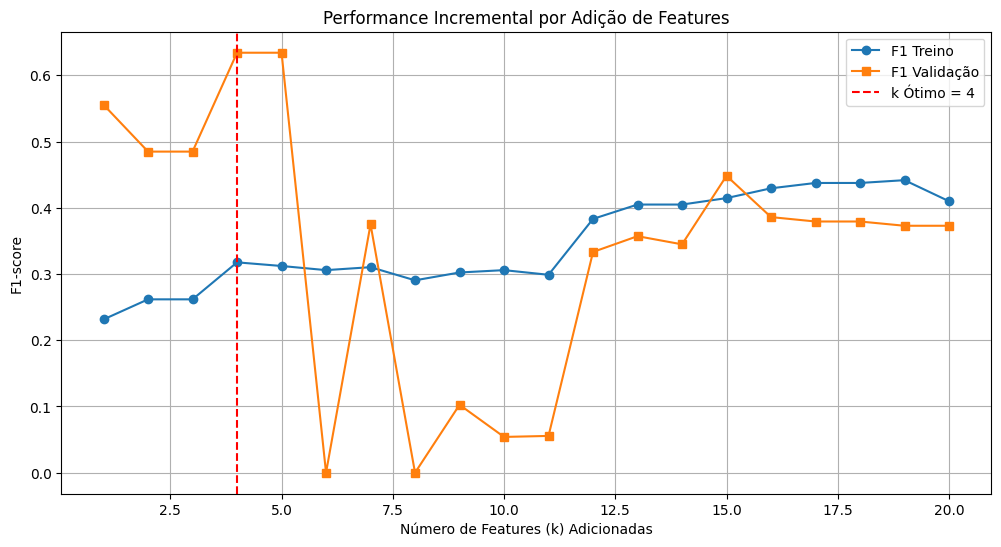

In [56]:
# --- Passo 1: Ranquear TODAS as features usando Informação Mútua (apenas nos dados de treino) ---
ranking_de_features = ranquear_features_por_info_mutua(X_train_scaled, y_train)

# --- Passo 2: Definir o modelo a ser usado (com Pipeline para robustez) ---
# Usar um modelo com regularização razoável, pois o número de features vai crescer.
modelo_teste_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='liblinear',
        penalty='l2',
        C=0.1, # Um C razoavelmente regularizador
        random_state=42,
        class_weight='balanced'
    ))
])

# --- Passo 3: Executar a avaliação incremental ---
df_performance_incremental = avaliar_adicao_incremental_de_features(
    X_treino_completo=X_train_scaled,
    y_treino=y_train,
    X_validacao_completo=X_validacao_scaled,
    y_validacao=y_validacao,
    ranking_features_df=ranking_de_features,
    modelo_template=modelo_teste_pipeline,
    max_features_a_testar=20 # Testar até as top 20 features
)

# --- Passo 4: Analisar os resultados ---
print("\n--- Resultado da Avaliação Incremental de Features ---")
print(df_performance_incremental.round(3).to_string())

if not df_performance_incremental.empty:
    # Encontrar o número de features (k) que maximizou o F1-score NA VALIDAÇÃO
    k_otimo = df_performance_incremental.loc[df_performance_incremental['f1_validacao'].idxmax()]
    print("\n--- Melhor Conjunto de Features Encontrado ---")
    print(k_otimo)
    
    # Plotar para visualização
    plt.figure(figsize=(12, 6))
    plt.plot(df_performance_incremental['num_features_k'], df_performance_incremental['f1_treino'], marker='o', label='F1 Treino')
    plt.plot(df_performance_incremental['num_features_k'], df_performance_incremental['f1_validacao'], marker='s', label='F1 Validação')
    plt.xlabel("Número de Features (k) Adicionadas")
    plt.ylabel("F1-score")
    plt.title("Performance Incremental por Adição de Features")
    plt.legend()
    plt.grid(True)
    # Adicionar uma linha vertical no k ótimo
    plt.axvline(x=k_otimo['num_features_k'], color='r', linestyle='--', label=f'k Ótimo = {int(k_otimo["num_features_k"])}')
    plt.legend() # Chamar de novo para incluir a linha
    plt.show()

In [61]:
n_features = 6

In [62]:
ranking_de_features.head(n_features)

,feature,mutual_info_score
0,ipca_dias_desde_mudanca,0.130344
1,close_norm_max,0.099199
2,close_norm_min,0.098026
3,retorno_medio_neg,0.093288
4,selic_dias_desde_mudanca,0.084318
5,obv_mean,0.069675


In [63]:
colunas = ranking_de_features['feature'].head(n_features).tolist()
colunas

['ipca_dias_desde_mudanca',
 'close_norm_max',
 'close_norm_min',
 'retorno_medio_neg',
 'selic_dias_desde_mudanca',
 'obv_mean']

In [64]:
X_train_subset = X_train[colunas]
X_validacao_subset = X_validacao[colunas]

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Criar um pipeline com o scaler e o modelo
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Normalização
    ('modelo', LogisticRegression(solver='liblinear', max_iter=5000, random_state=42))
])

In [66]:
modelo_otimizado = tr.otimizar_hiperparametros_logreg(X_train_subset, y_train, n_splits_cv=5, pipeline_template=pipeline)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.1127
Melhores Parâmetros Encontrados:
{'modelo__C': np.float64(10.0), 'modelo__penalty': 'l1', 'modelo__solver': 'saga'}


Pipeline(steps=[('scaler', StandardScaler()),
                ('modelo',
                 LogisticRegression(C=np.float64(10.0), max_iter=5000,
                                    penalty='l1', random_state=42,
                                    solver='saga'))])

AUC no treino: 0.691
AUC na validação: 0.818
Diferença AUC (Treino - Validação): -0.128
PR AUC no treino: 0.415
PR AUC na validação: 0.440
Diferença PR AUC (Treino - Validação): -0.024
F1 Score no treino: 0.324
F1 Score na validação: 0.063


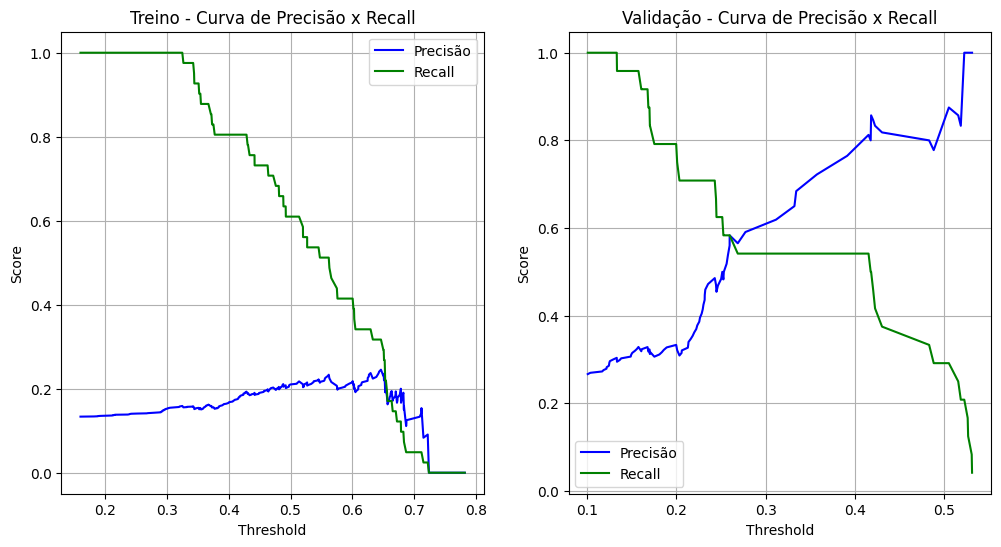

(np.float64(0.6906660450103926),
 np.float64(0.8183255916093374),
 np.float64(-0.12765954659894474),
 np.float64(0.41532692327800835),
 np.float64(0.4397318814996076),
 np.float64(0.3235141439993536),
 np.float64(0.06329307568438004))

In [67]:
class_weight = 'balanced' #{0:1, 1:3}  # Ajustar pesos para lidar com desbalanceamento
modelo_rl = LogisticRegression(solver='saga', max_iter=5000,random_state=42, class_weight=class_weight, C=10, penalty='l2')

pipeline_rl = Pipeline([
    ('scaler', StandardScaler()),  # Normalização
    ('modelo', modelo_rl)
])

pipeline_rl.fit(X_train_subset, y_train)
tr.comparar_auc_conjuntos(pipeline_rl, X_train_subset, y_train, X_validacao_subset, y_validacao)

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 313583328458643828).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/313583328458643828
MLflow Run ID: b648ab2e1dfb44c0b0bf3d9788d051b4 para ITUB4.SA_15dias_x_0.03val_5dias_alvo
AUC no treino: 0.597
AUC na validação: 0.669

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.49
  Precisão Média Esperada: 22.52%
  Recall Médio Esperado: 100.00%
  Janelas Usadas para Precisão: 278.0

Threshold ideal baseado em mínimo recall ou precisão: 0.49

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.237
Recall médio: 1.000
Sinais de compra presentes na vallidação: 31.0
Sinais de compra previstos na validação: 90
Modelo ITUB4.SA_15dias_x_0.03val_5dias_alvo salvo na run b648ab2e1dfb44c0b0bf3d9788d051b4


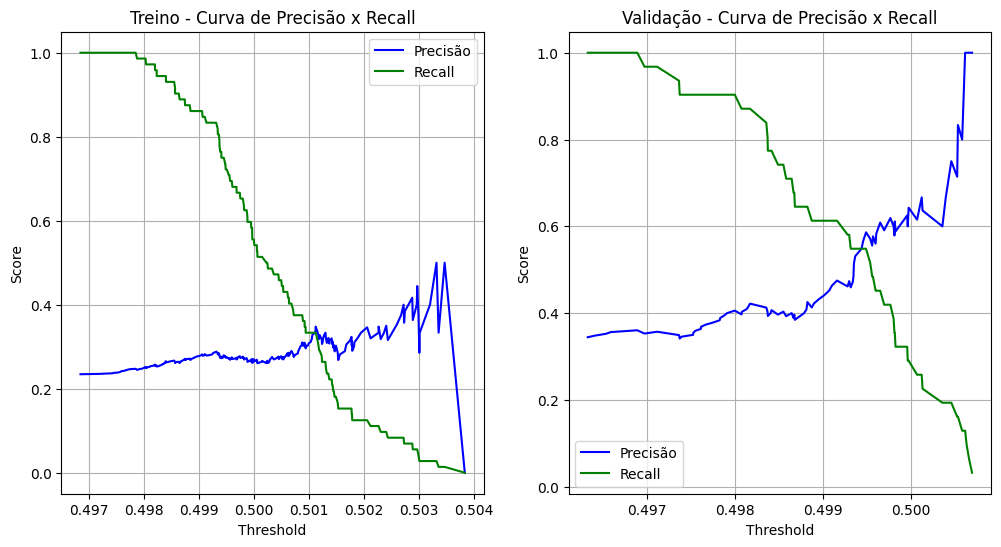

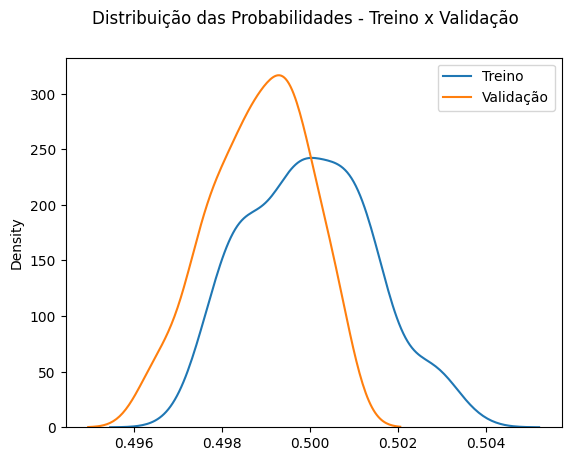

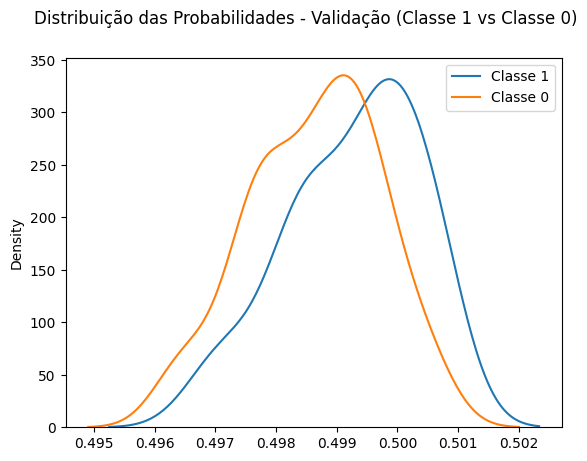

In [ ]:
recall_minimo = None
precisao_minima = None
threshold_fixo = 0.49
resultado = tr.avaliar_e_logar_modelo(pipeline_rl, papel, X_train_subset, y_train, X_validacao_subset, y_validacao, dias_janela_x=dias_entrada, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima, threshold_fixo=threshold_fixo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']